# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

## Evaluation Settings

In [ ]:
DATA_FREQUENCY = 'H' # '15min'
USE_RESIDUAL = True  # If True, model the residuals (1-step differencing) instead of the original target.
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 10

In [5]:
# Measure loading time
start_time = time.time()

# Load data

train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_1h_wfv', use_numpy=True)
ALL_FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
                'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                'powerfactor3_lag_1h', 'powerfactor3_lag_24h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.04 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(672, 43), y=(672,)
First valid split shape: X=(672, 43), y=(672,)

Memory usage:
Train: 6.32 MB
Valid: 1.40 MB
Test: 0.41 MB
Total: 8.13 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [ ]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-10-18 13:00:00+02:00

Time: 0.02 seconds
Predicting for chunk from 2022-10-18 14:00:00+02:00 to 2022-11-01 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-11-01 13:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2022-11-01 14:00:00+01:00 to 2022-11-15 12:00:00+01:00

-------------------------
Model's memory usage: 0.024620 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2581
	MAE: 0.1554
	MAPE: 19.4316%

Directional Metrics:
	Directional Accuracy: 42.4739%
	First-Diff Correlation: -0.0553

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.0769
		F1: 0.1250
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection 

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-11-15 12:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2022-11-15 13:00:00+01:00 to 2022-11-29 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-11-29 13:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2022-11-29 14:00:00+01:00 to 2022-12-13 12:00:00+01:00

-------------------------
Model's memory usage: 0.024483 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2131
	MAE: 0.1337
	MAPE: 25.7555%

Directional Metrics:
	Directional Accuracy: 43.6662%
	First-Diff Correlation: 0.2416

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-03-07 12:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2023-03-07 13:00:00+01:00 to 2023-03-21 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-03-21 13:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2023-03-21 14:00:00+01:00 to 2023-04-04 13:00:00+02:00

-------------------------
Model's memory usage: 0.024391 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2062
	MAE: 0.1322
	MAPE: 30.8266%

Directional Metrics:
	Directional Accuracy: 40.3875%
	First-Diff Correlation: 0.1573

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2667
		Recall: 0.2105
		F1: 0.2353
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-04-04 13:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-04-04 14:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------
Model's memory usage: 0.024376 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1500
	MAE: 0.0843
	MAPE: 24.8118%

Directional Metrics:
	Directional Accuracy: 54.4776%
	First-Diff Correlation: 0.5102

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.4000
		Recall: 0.6667
		F1: 0.5000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6000
		Recall: 1.0000
		F1: 0.7500
	Drops:
		Precision: 0.6000
		Recall: 1.0000
		F1: 0.7500
------------------------------------------

#### Results

In [9]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1890 ± 0.0410
	MAE: 0.1170 ± 0.0285
	MAPE: 25.7271% ± 5.4483%

	Directional Metrics:
		Directional Accuracy: 45.7429% ± 8.8793%
		First-Diff Correlation: 0.2882 ± 0.1977

	Immediate Detection (delta=0):
		Spike Precision: 0.2353 ± 0.1488
		Spike Recall: 0.2140 ± 0.2096
		Spike F1: 0.2072 ± 0.1612
		Drop Precision: 0.0359 ± 0.0430
		Drop Recall: 0.0321 ± 0.0398
		Drop F1: 0.0338 ± 0.0411

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7487 ± 0.3313
		Spike Recall: 0.6209 ± 0.3393
		Spike F1: 0.6393 ± 0.3078
		Drop Precision: 0.2798 ± 0.2194
		Drop Recall: 0.3113 ± 0.3216
		Drop F1: 0.2870 ± 0.2505
Daily Metrics:
	RMSE: 0.1375 ± 0.0527
	MAE: 0.0809 ± 0.0248
	MAPE: 0.8097% ± 0.2223%

	Directional Metrics:
		Directional Accuracy: 91.6667% ± 11.2938%
		First-Diff Correlation: 0.9998 ± 0.0001

	Immediate Detection (delta=0):

#### Validation plots

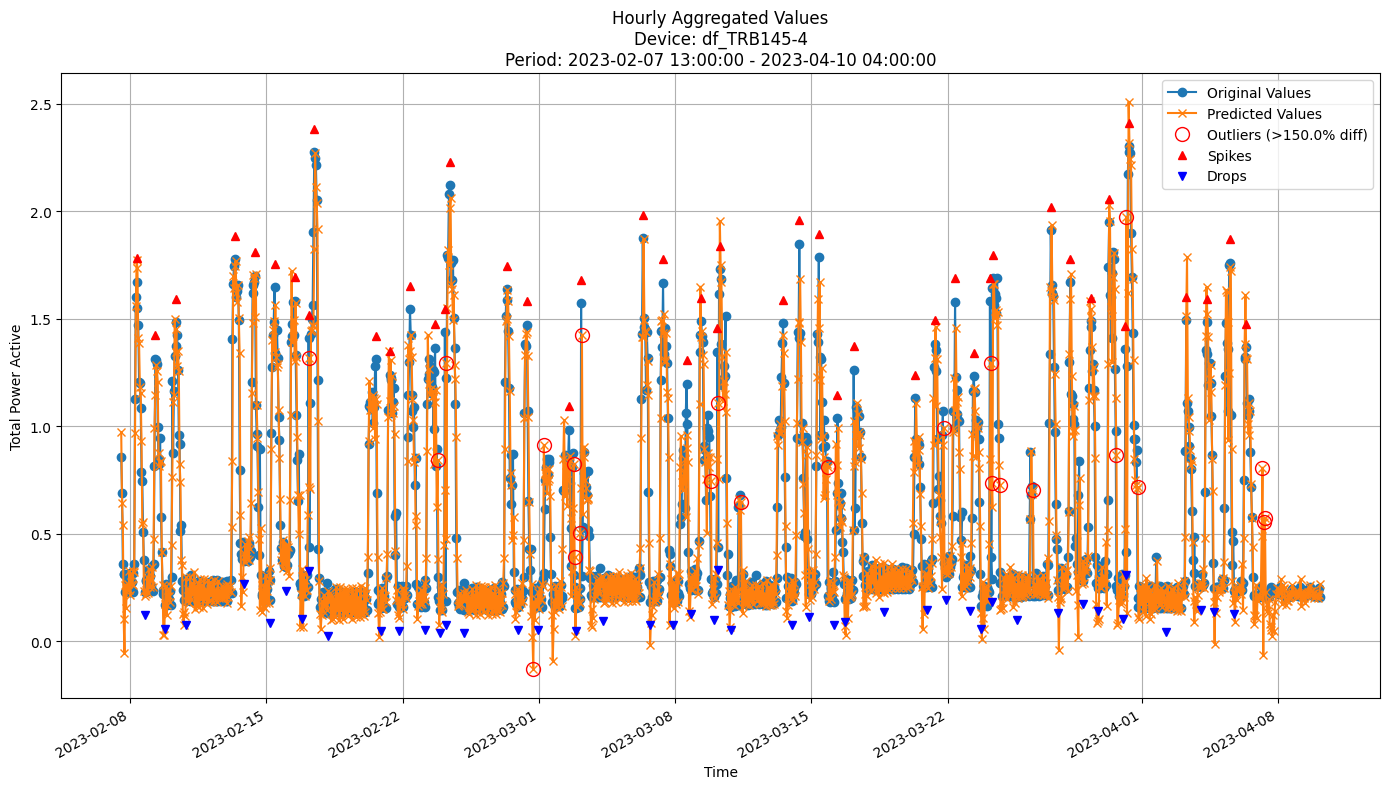


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1887
MAE: 0.1208
MAPE: 31.0850%

Directional Metrics:
Directional Accuracy: 39.3775%
First-Diff Correlation: 0.1937

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2162
  Recall: 0.1739
  F1 Score: 0.1928
Drops:
  Precision: 0.0556
  Recall: 0.0444
  F1 Score: 0.0494

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8649
  Recall: 0.6957
  F1 Score: 0.7711
Drops:
  Precision: 0.3056
  Recall: 0.2444
  F1 Score: 0.2716


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [11]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {'is_residual': True}

In [ ]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 0.000511 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2575
	MAE: 0.1510
	MAPE: 17.5130%

Directional Metrics:
	Directional Accuracy: 34.4262%
	First-Diff Correlation: -0.0298

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
---------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 0.000504 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2538
	MAE: 0.1422
	MAPE: 23.3583%

Directional Metrics:
	Directional Accuracy: 39.6423%
	First-Diff Correlation: 0.2422

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 0.000473 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2420
	MAE: 0.1427
	MAPE: 30.5933%

Directional Metrics:
	Directional Accuracy: 37.4069%
	First-Diff Correlation: -0.0237

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
---------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 0.000465 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1473
	MAE: 0.0628
	MAPE: 11.6539%

Directional Metrics:
	Directional Accuracy: 40.2985%
	First-Diff Correlation: 0.4767

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
----------------------------------------------

#### Results

In [13]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2270 ± 0.0423
	MAE: 0.1280 ± 0.0315
	MAPE: 23.8618% ± 7.5965%

	Directional Metrics:
		Directional Accuracy: 39.1825% ± 4.8386%
		First-Diff Correlation: 0.1865 ± 0.1993

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8571 ± 0.3499
		Spike Recall: 0.8571 ± 0.3499
		Spike F1: 0.8571 ± 0.3499
		Drop Precision: 0.8482 ± 0.3470
		Drop Recall: 0.8571 ± 0.3499
		Drop F1: 0.8525 ± 0.3482
Daily Metrics:
	RMSE: 0.3571 ± 0.0446
	MAE: 0.1464 ± 0.0140
	MAPE: 1.7122% ± 0.7817%

	Directional Metrics:
		Directional Accuracy: 94.0476% ± 6.5205%
		First-Diff Correlation: 0.9991 ± 0.0003

	Immediate Detection (delta=0):


#### Validation plots

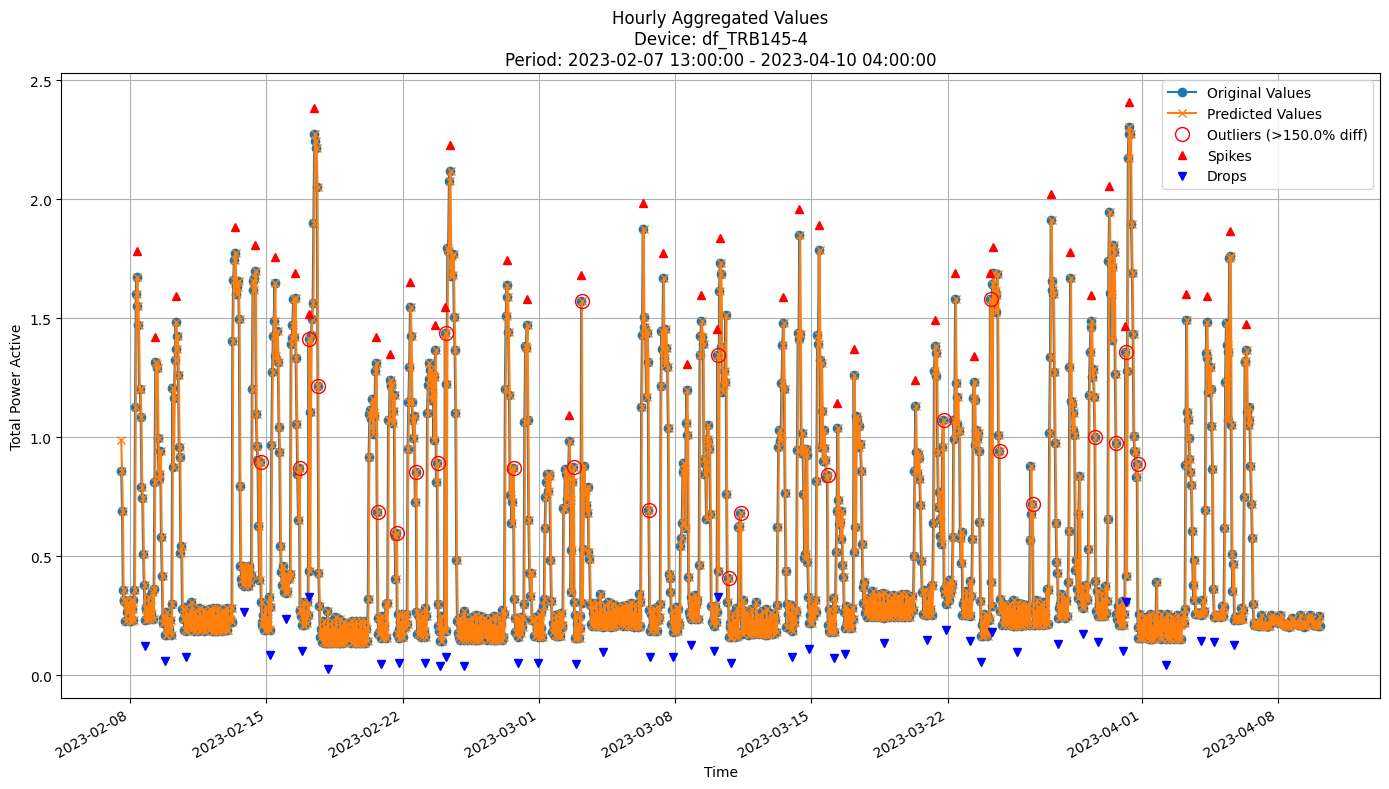


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2333
MAE: 0.1327
MAPE: 29.8270%

Directional Metrics:
Directional Accuracy: 36.9418%
First-Diff Correlation: -0.0126

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [15]:
update_freq = "14D"  # Update the model every 14 days

gbdt = GradientBoostingRegressor
gbdt_params = dict(n_estimators=100, learning_rate=0.03, subsample=0.8, max_depth=10, random_state=42)

In [ ]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt, 
    model_params=gbdt_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-10-18 13:00:00+02:00

Time: 1.39 seconds
Predicting for chunk from 2022-10-18 14:00:00+02:00 to 2022-11-01 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-11-01 13:00:00+01:00

Time: 2.15 seconds
Predicting for chunk from 2022-11-01 14:00:00+01:00 to 2022-11-15 12:00:00+01:00

-------------------------
Model's memory usage: 0.010811 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2765
	MAE: 0.1804
	MAPE: 25.0493%

Directional Metrics:
	Directional Accuracy: 42.7720%
	First-Diff Correlation: 0.0366

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-11-15 12:00:00+01:00

Time: 2.85 seconds
Predicting for chunk from 2022-11-15 13:00:00+01:00 to 2022-11-29 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-11-29 13:00:00+01:00

Time: 3.61 seconds
Predicting for chunk from 2022-11-29 14:00:00+01:00 to 2022-12-13 12:00:00+01:00

-------------------------
Model's memory usage: 0.010735 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2272
	MAE: 0.1418
	MAPE: 28.0063%

Directional Metrics:
	Directional Accuracy: 44.7094%
	First-Diff Correlation: 0.3324

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-03-07 12:00:00+01:00

Time: 8.98 seconds
Predicting for chunk from 2023-03-07 13:00:00+01:00 to 2023-03-21 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-03-21 13:00:00+01:00

Time: 9.84 seconds
Predicting for chunk from 2023-03-21 14:00:00+01:00 to 2023-04-04 13:00:00+02:00

-------------------------
Model's memory usage: 0.010429 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2073
	MAE: 0.1341
	MAPE: 31.3596%

Directional Metrics:
	Directional Accuracy: 34.7243%
	First-Diff Correlation: 0.0968

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.2632
		F1: 0.2941
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-04-04 13:00:00+02:00

Time: 10.69 seconds
Predicting for chunk from 2023-04-04 14:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------
Model's memory usage: 0.010391 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1411
	MAE: 0.0719
	MAPE: 17.2353%

Directional Metrics:
	Directional Accuracy: 41.0448%
	First-Diff Correlation: 0.4363

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.2500
		Recall: 0.3333
		F1: 0.2857
-----------------------------------------

#### Results

In [17]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0530 ± 0.0137
	MAE: 0.0348 ± 0.0072
	MAPE: 7.6897% ± 1.7522%

	Directional Metrics:
		Directional Accuracy: 73.2727% ± 6.5050%
		First-Diff Correlation: 0.9342 ± 0.0337

	Immediate Detection (delta=0):
		Spike Precision: 0.4266 ± 0.3961
		Spike Recall: 0.3602 ± 0.3519
		Spike F1: 0.3867 ± 0.3655
		Drop Precision: 0.0910 ± 0.1056
		Drop Recall: 0.0821 ± 0.1052
		Drop F1: 0.0857 ± 0.1052

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5238 ± 0.4580
		Spike Recall: 0.4406 ± 0.3979
		Spike F1: 0.4742 ± 0.4178
		Drop Precision: 0.1266 ± 0.1347
		Drop Recall: 0.1150 ± 0.1328
		Drop F1: 0.1199 ± 0.1336
Daily Metrics:
	RMSE: 0.1573 ± 0.0593
	MAE: 0.1092 ± 0.0372
	MAPE: 0.7944% ± 0.2837%

	Directional Metrics:
		Directional Accuracy: 97.2850% ± 2.1286%
		First-Diff Correlation: 0.9997 ± 0.0002

	Immediate Detection (delta=0):
	

#### Training plots

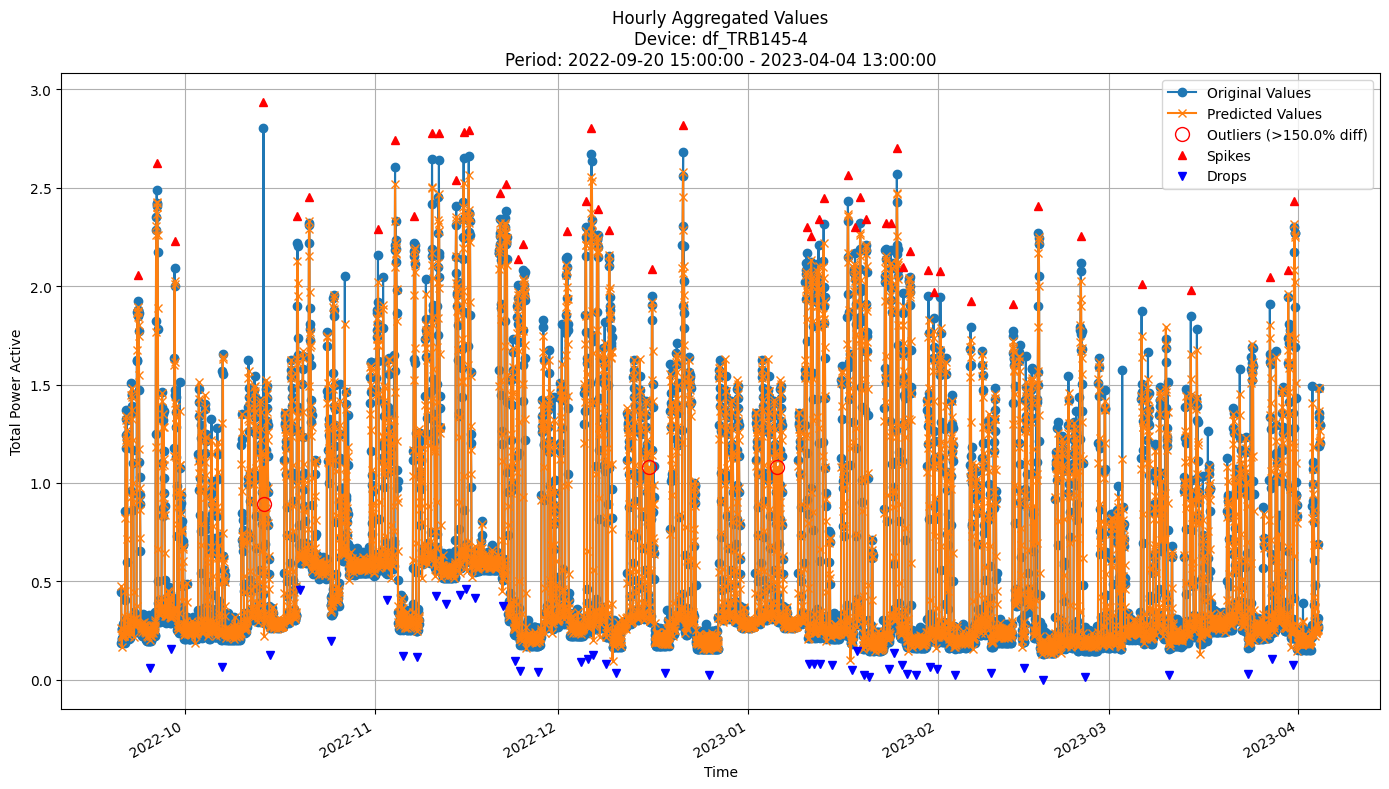


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0700
MAE: 0.0461
MAPE: 10.7995%

Directional Metrics:
Directional Accuracy: 62.7180%
First-Diff Correlation: 0.8856

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5625
  Recall: 0.5400
  F1 Score: 0.5510
Drops:
  Precision: 0.1064
  Recall: 0.1020
  F1 Score: 0.1042

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8333
  Recall: 0.8000
  F1 Score: 0.8163
Drops:
  Precision: 0.2340
  Recall: 0.2245
  F1 Score: 0.2292


In [18]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

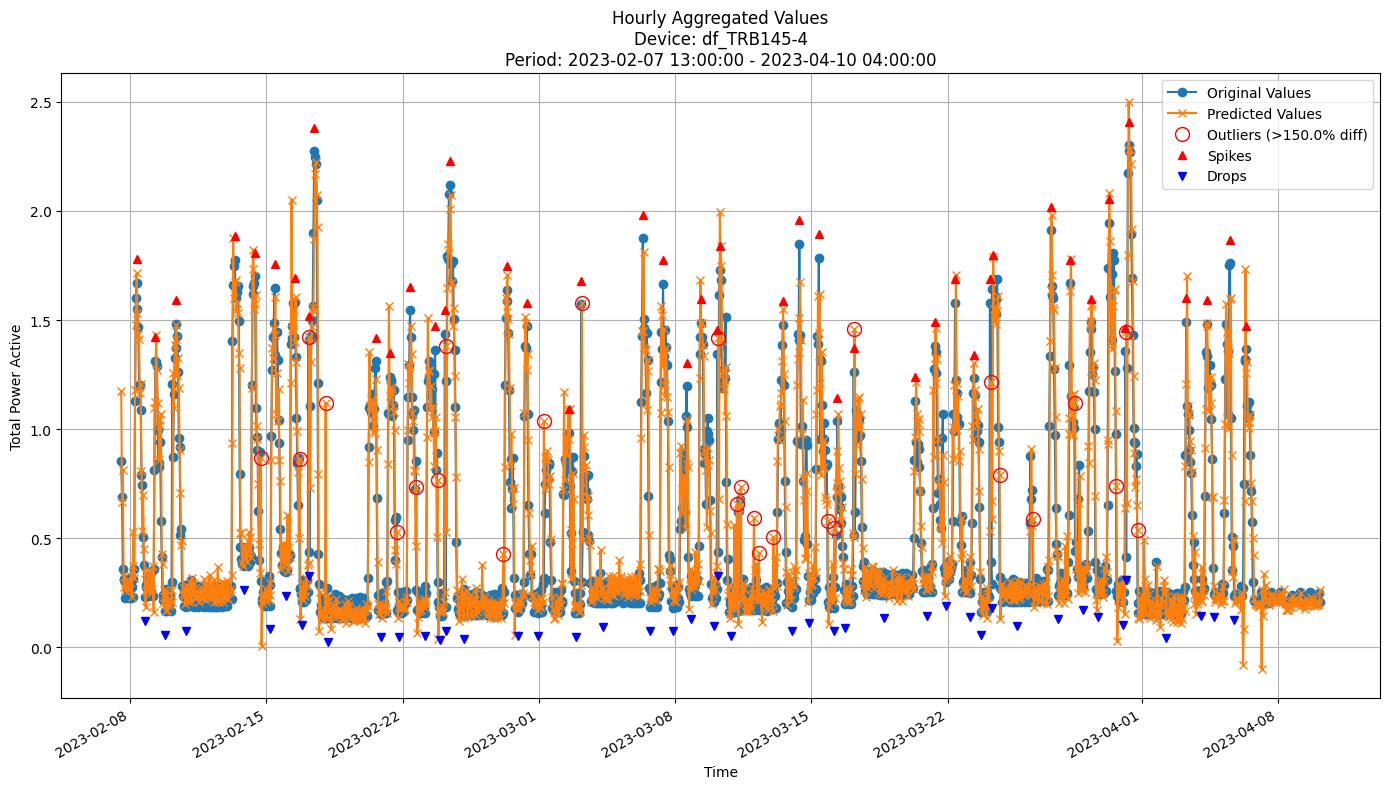


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1957
MAE: 0.1183
MAPE: 28.8017%

Directional Metrics:
Directional Accuracy: 38.1597%
First-Diff Correlation: 0.1480

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1842
  Recall: 0.1522
  F1 Score: 0.1667
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7632
  Recall: 0.6304
  F1 Score: 0.6905
Drops:
  Precision: 0.2432
  Recall: 0.2000
  F1 Score: 0.2195


In [19]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# Basic Prediction Metrics:
# RMSE: 0.2195
# MAE: 0.1398
# MAPE: 33.6987%

### Random Forest model

In [20]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = dict(n_estimators=100, max_depth=10, max_features='sqrt', random_state=42, n_jobs=-1)

In [ ]:

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-10-18 13:00:00+02:00

Time: 0.13 seconds
Predicting for chunk from 2022-10-18 14:00:00+02:00 to 2022-11-01 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-11-01 13:00:00+01:00

Time: 0.11 seconds
Predicting for chunk from 2022-11-01 14:00:00+01:00 to 2022-11-15 12:00:00+01:00

-------------------------
Model's memory usage: 0.042160 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2339
	MAE: 0.1509
	MAPE: 19.5828%

Directional Metrics:
	Directional Accuracy: 35.9165%
	First-Diff Correlation: 0.0213

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1250
		Recall: 0.0769
		F1: 0.0952
	Drops:
		Precision: 0.1250
		Recall: 0.0769
		F1: 0.0952

Delayed Detection (

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-11-15 12:00:00+01:00

Time: 0.12 seconds
Predicting for chunk from 2022-11-15 13:00:00+01:00 to 2022-11-29 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2022-11-29 13:00:00+01:00

Time: 0.12 seconds
Predicting for chunk from 2022-11-29 14:00:00+01:00 to 2022-12-13 12:00:00+01:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2077
	MAE: 0.1348
	MAPE: 27.2083%

Directional Metrics:
	Directional Accuracy: 41.1326%
	First-Diff Correlation: 0.3544

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-03-07 12:00:00+01:00

Time: 0.18 seconds
Predicting for chunk from 2023-03-07 13:00:00+01:00 to 2023-03-21 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-03-21 13:00:00+01:00

Time: 0.20 seconds
Predicting for chunk from 2023-03-21 14:00:00+01:00 to 2023-04-04 13:00:00+02:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2076
	MAE: 0.1280
	MAPE: 29.7553%

Directional Metrics:
	Directional Accuracy: 35.6185%
	First-Diff Correlation: 0.0489

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.2632
		F1: 0.2941
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-04-04 13:00:00+02:00

Time: 0.21 seconds
Predicting for chunk from 2023-04-04 14:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1140
	MAE: 0.0544
	MAPE: 11.9458%

Directional Metrics:
	Directional Accuracy: 52.9851%
	First-Diff Correlation: 0.5459

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
------------------------------------------

#### Results

In [22]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1172 ± 0.0100
	MAE: 0.0686 ± 0.0075
	MAPE: 13.6571% ± 1.7935%

	Directional Metrics:
		Directional Accuracy: 48.3320% ± 6.2587%
		First-Diff Correlation: 0.6510 ± 0.0573

	Immediate Detection (delta=0):
		Spike Precision: 0.1457 ± 0.1608
		Spike Recall: 0.1160 ± 0.1553
		Spike F1: 0.1271 ± 0.1561
		Drop Precision: 0.0792 ± 0.0794
		Drop Recall: 0.0597 ± 0.0701
		Drop F1: 0.0668 ± 0.0724

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5254 ± 0.4568
		Spike Recall: 0.3879 ± 0.3674
		Spike F1: 0.4396 ± 0.3949
		Drop Precision: 0.1350 ± 0.1235
		Drop Recall: 0.1009 ± 0.1068
		Drop F1: 0.1135 ± 0.1111
Daily Metrics:
	RMSE: 0.3132 ± 0.0486
	MAE: 0.2387 ± 0.0368
	MAPE: 1.6761% ± 0.2809%

	Directional Metrics:
		Directional Accuracy: 96.6193% ± 1.6989%
		First-Diff Correlation: 0.9991 ± 0.0003

	Immediate Detection (delta=0):


#### Training plots
Plot only the last period of predictions

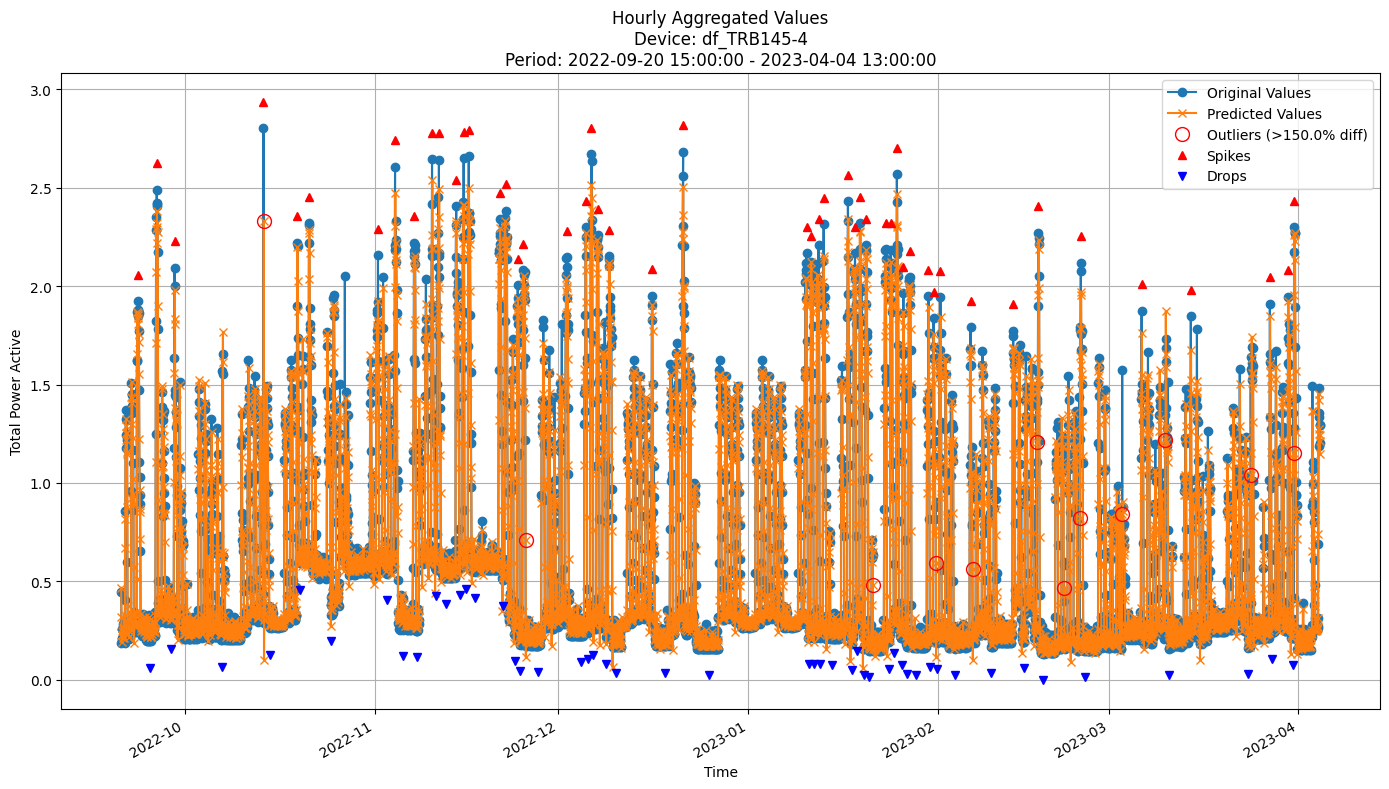


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1308
MAE: 0.0780
MAPE: 16.8851%

Directional Metrics:
Directional Accuracy: 43.1519%
First-Diff Correlation: 0.5657

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1250
  Recall: 0.1000
  F1 Score: 0.1111
Drops:
  Precision: 0.0769
  Recall: 0.0612
  F1 Score: 0.0682

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8500
  Recall: 0.6800
  F1 Score: 0.7556
Drops:
  Precision: 0.1795
  Recall: 0.1429
  F1 Score: 0.1591


In [23]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

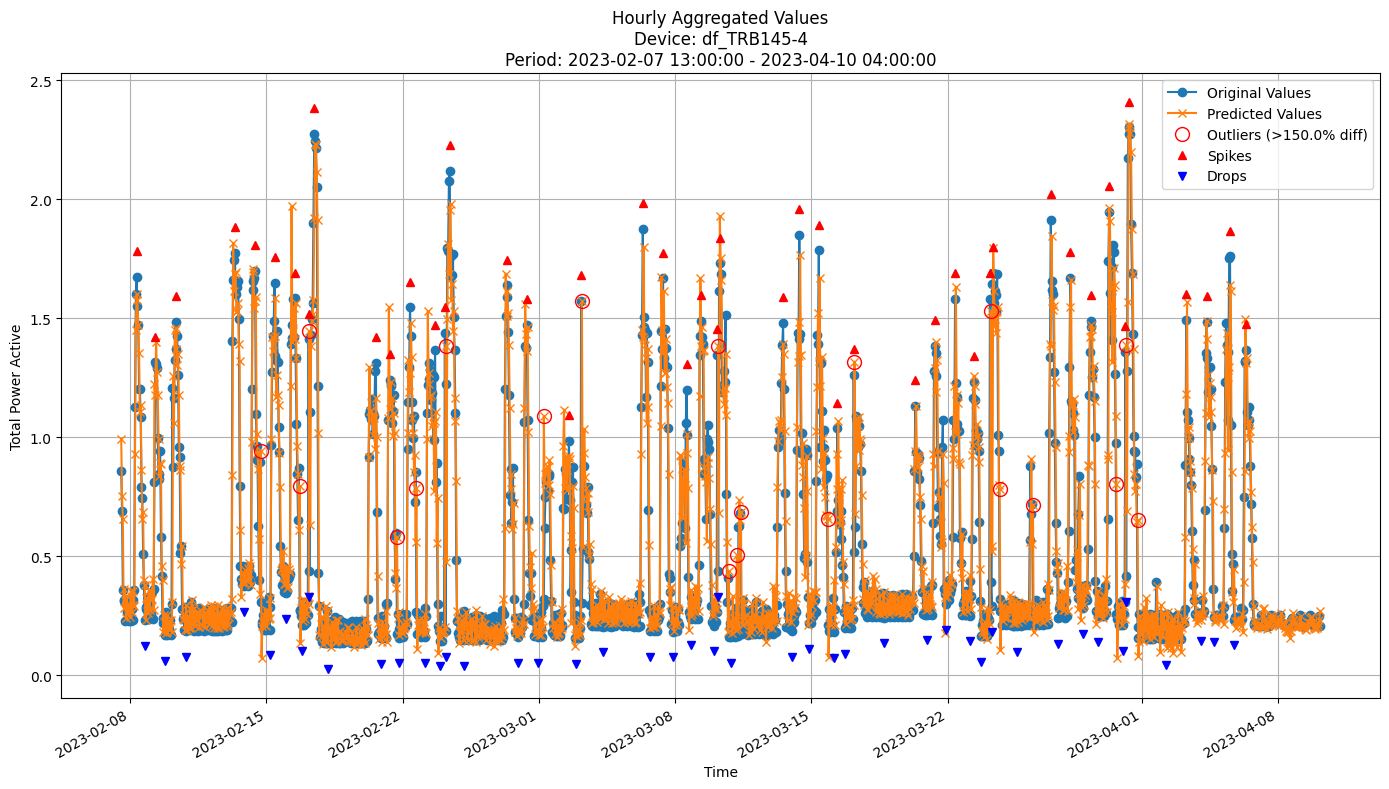


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1936
MAE: 0.1141
MAPE: 27.6028%

Directional Metrics:
Directional Accuracy: 37.8890%
First-Diff Correlation: 0.1222

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2368
  Recall: 0.1957
  F1 Score: 0.2143
Drops:
  Precision: 0.0270
  Recall: 0.0222
  F1 Score: 0.0244

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8158
  Recall: 0.6739
  F1 Score: 0.7381
Drops:
  Precision: 0.3243
  Recall: 0.2667
  F1 Score: 0.2927


In [24]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [25]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = dict(max_depth=10, grace_period=10, delta=0.5, tau=0.05, leaf_prediction="mean")


In [ ]:

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 2.391357 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2530
	MAE: 0.1526
	MAPE: 18.7462%

Directional Metrics:
	Directional Accuracy: 40.5365%
	First-Diff Correlation: 0.0021

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9231
		Recall: 0.9231
		F1: 0.9231
	Drops:
		Precision: 0.3846
		Recall: 0.3846
		F1: 0.3846
----------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 3.102631 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2436
	MAE: 0.1474
	MAPE: 26.1445%

Directional Metrics:
	Directional Accuracy: 40.3875%
	First-Diff Correlation: 0.2255

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 4.489899 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2249
	MAE: 0.1412
	MAPE: 33.3025%

Directional Metrics:
	Directional Accuracy: 38.5991%
	First-Diff Correlation: 0.0227

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.5000
		Recall: 0.2632
		F1: 0.3448
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.5263
		F1: 0.6897
	Drops:
		Precision: 0.5000
		Recall: 0.2500
		F1: 0.3333
----------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 4.679893 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1453
	MAE: 0.0861
	MAPE: 25.2931%

Directional Metrics:
	Directional Accuracy: 47.7612%
	First-Diff Correlation: 0.4327

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
----------------------------------------------

#### Results

In [27]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2257 ± 0.0101
	MAE: 0.1285 ± 0.0053
	MAPE: 24.4614% ± 2.2440%

	Directional Metrics:
		Directional Accuracy: 43.9481% ± 0.8747%
		First-Diff Correlation: 0.1291 ± 0.0825

	Immediate Detection (delta=0):
		Spike Precision: 0.0870 ± 0.1042
		Spike Recall: 0.0450 ± 0.0527
		Spike F1: 0.0592 ± 0.0698
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5731 ± 0.4048
		Spike Recall: 0.3913 ± 0.3142
		Spike F1: 0.4146 ± 0.2630
		Drop Precision: 0.0533 ± 0.0671
		Drop Recall: 0.0271 ± 0.0330
		Drop F1: 0.0359 ± 0.0441
Daily Metrics:
	RMSE: 0.6645 ± 0.0752
	MAE: 0.5197 ± 0.0470
	MAPE: 4.2787% ± 0.5487%

	Directional Metrics:
		Directional Accuracy: 92.5158% ± 2.0364%
		First-Diff Correlation: 0.9957 ± 0.0013

	Immediate Detection (delta=0):


#### Training plots
Plot only the last period of predictions

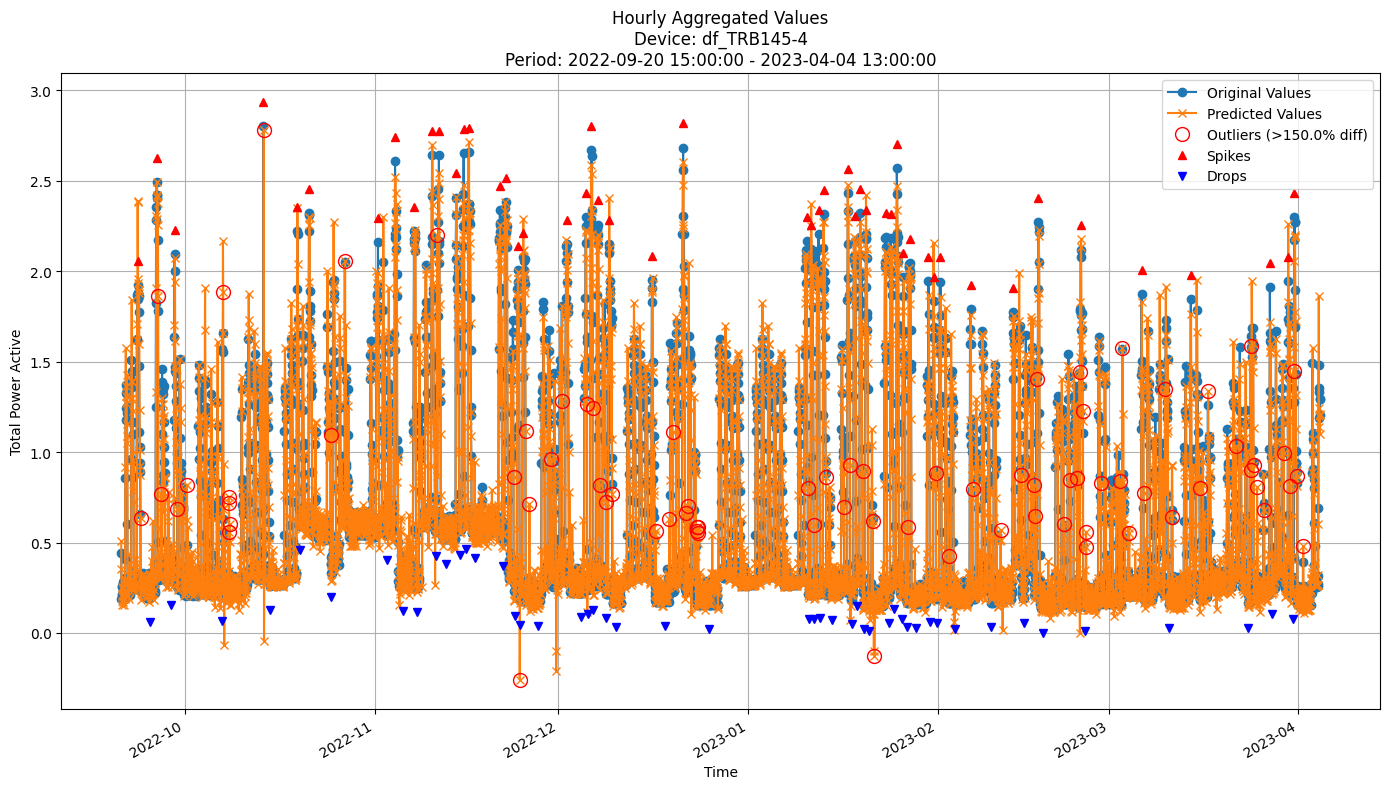


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2190
MAE: 0.1289
MAPE: 26.7757%

Directional Metrics:
Directional Accuracy: 42.9604%
First-Diff Correlation: 0.1804

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2308
  Recall: 0.1200
  F1 Score: 0.1579
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8846
  Recall: 0.4600
  F1 Score: 0.6053
Drops:
  Precision: 0.1200
  Recall: 0.0612
  F1 Score: 0.0811


In [28]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

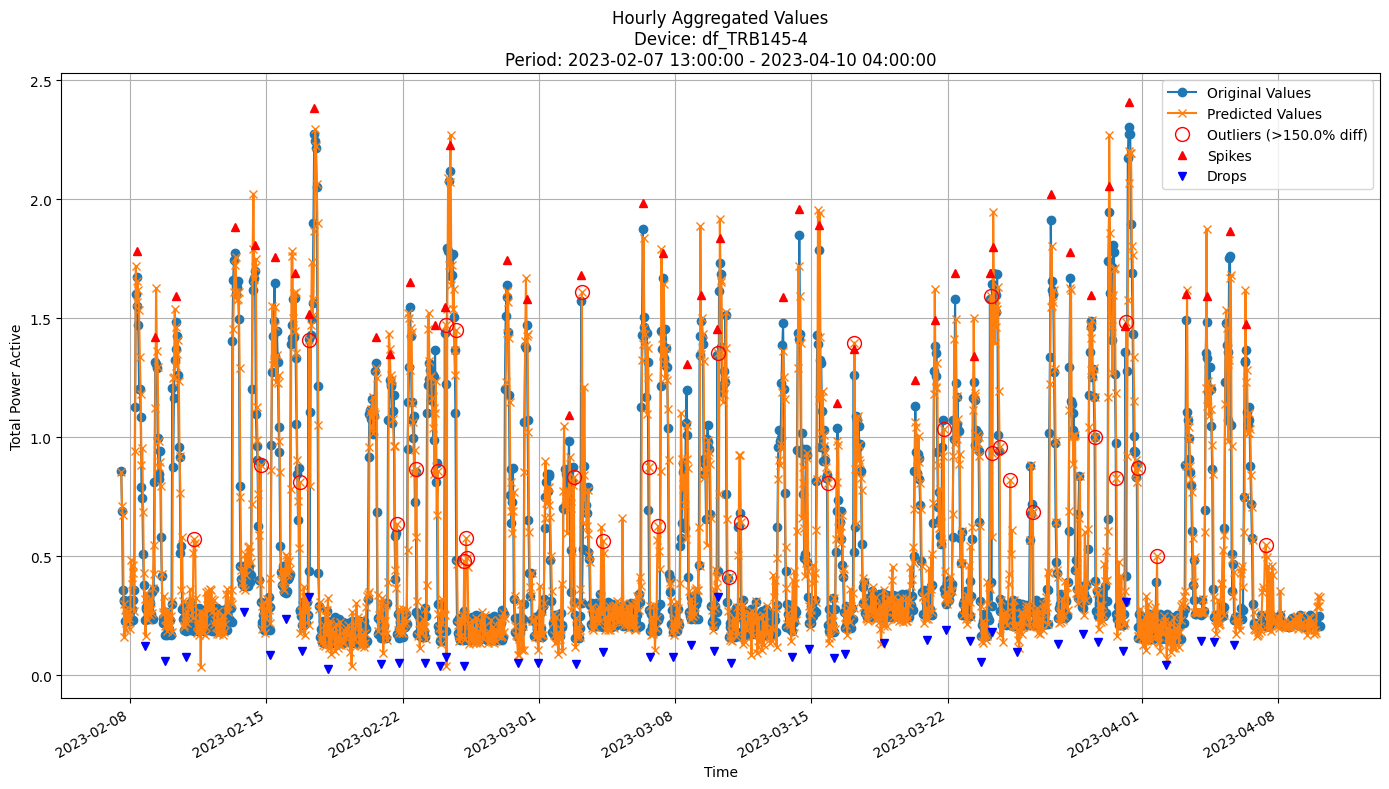


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2199
MAE: 0.1346
MAPE: 33.7003%

Directional Metrics:
Directional Accuracy: 40.1218%
First-Diff Correlation: 0.0462

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2000
  Recall: 0.1304
  F1 Score: 0.1579
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8333
  Recall: 0.5435
  F1 Score: 0.6579
Drops:
  Precision: 0.3793
  Recall: 0.2444
  F1 Score: 0.2973


In [29]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [30]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = dict(n_models=10, 
                     max_features=0.8, 
                     aggregation_method='median', 
                     grace_period=10, 
                     max_depth=10, 
                     delta=0.5, 
                     tau=0.01, 
                     seed=42)


In [ ]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 10.648346 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2420
	MAE: 0.1434
	MAPE: 17.1413%

Directional Metrics:
	Directional Accuracy: 33.0849%
	First-Diff Correlation: -0.0123

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9231
		Recall: 0.9231
		F1: 0.9231
	Drops:
		Precision: 0.6154
		Recall: 0.6154
		F1: 0.6154
--------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 14.344055 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2307
	MAE: 0.1313
	MAPE: 22.8291%

Directional Metrics:
	Directional Accuracy: 40.3875%
	First-Diff Correlation: 0.2663

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
---------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 22.207924 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2196
	MAE: 0.1318
	MAPE: 30.0914%

Directional Metrics:
	Directional Accuracy: 38.1520%
	First-Diff Correlation: -0.0071

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1333
		Recall: 0.1053
		F1: 0.1176
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7895
		F1: 0.8824
	Drops:
		Precision: 0.4375
		Recall: 0.3500
		F1: 0.3889
--------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 22.712738 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1144
	MAE: 0.0592
	MAPE: 13.8774%

Directional Metrics:
	Directional Accuracy: 52.9851%
	First-Diff Correlation: 0.5619

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.6667
		Recall: 0.6667
		F1: 0.6667
---------------------------------------------

#### Results

In [32]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2138 ± 0.0102
	MAE: 0.1169 ± 0.0045
	MAPE: 21.3893% ± 1.5761%

	Directional Metrics:
		Directional Accuracy: 41.4328% ± 1.7356%
		First-Diff Correlation: 0.1375 ± 0.0822

	Immediate Detection (delta=0):
		Spike Precision: 0.0229 ± 0.0378
		Spike Recall: 0.0134 ± 0.0216
		Spike F1: 0.0169 ± 0.0274
		Drop Precision: 0.0075 ± 0.0184
		Drop Recall: 0.0075 ± 0.0184
		Drop F1: 0.0075 ± 0.0184

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6942 ± 0.4401
		Spike Recall: 0.4230 ± 0.3256
		Spike F1: 0.5103 ± 0.3494
		Drop Precision: 0.1304 ± 0.1729
		Drop Recall: 0.1058 ± 0.1633
		Drop F1: 0.1150 ± 0.1661
Daily Metrics:
	RMSE: 0.3369 ± 0.0349
	MAE: 0.2543 ± 0.0240
	MAPE: 2.1072% ± 0.2070%

	Directional Metrics:
		Directional Accuracy: 94.6453% ± 1.6277%
		First-Diff Correlation: 0.9990 ± 0.0002

	Immediate Detection (delta=0):


#### Training plots

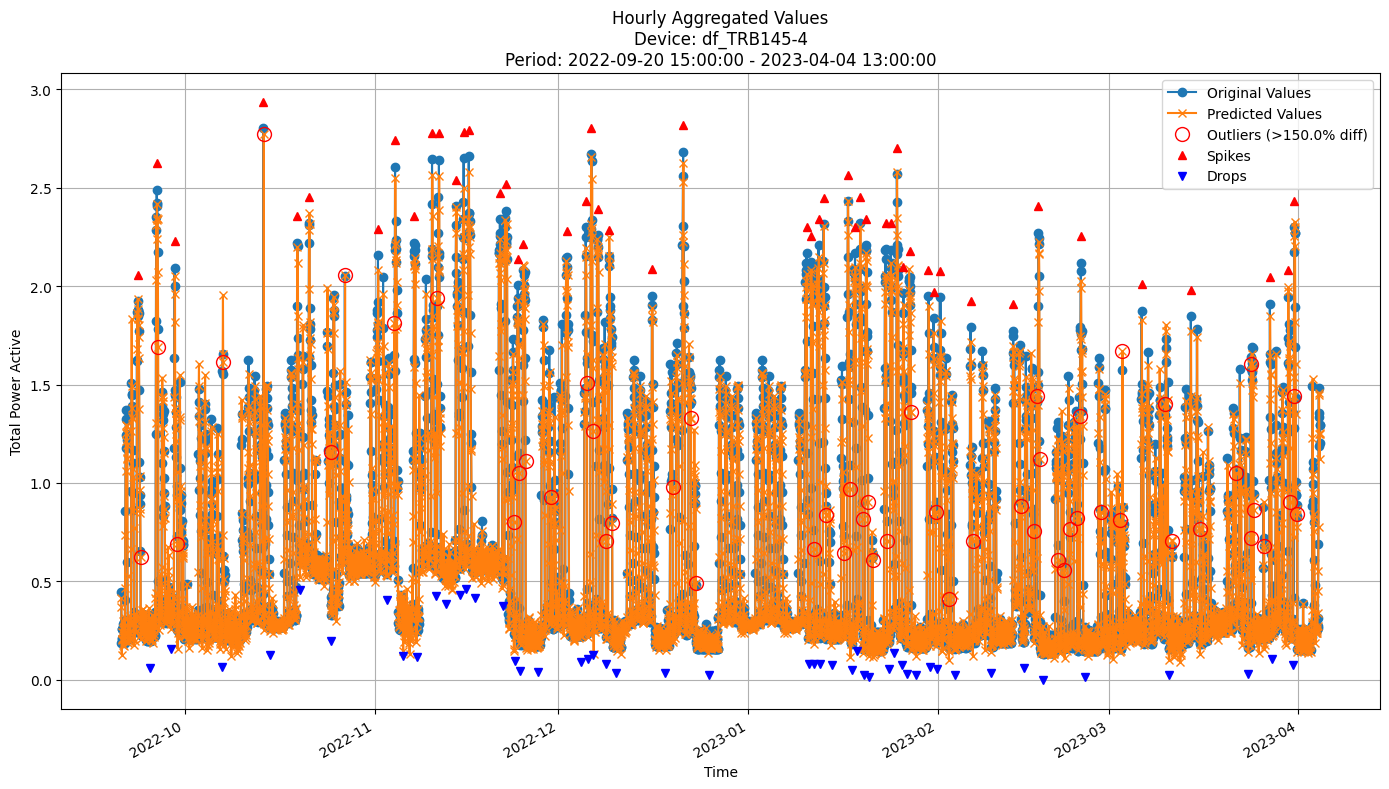


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2078
MAE: 0.1179
MAPE: 23.4015%

Directional Metrics:
Directional Accuracy: 42.0459%
First-Diff Correlation: 0.1731

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0606
  Recall: 0.0400
  F1 Score: 0.0482
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9091
  Recall: 0.6000
  F1 Score: 0.7229
Drops:
  Precision: 0.2812
  Recall: 0.1837
  F1 Score: 0.2222


In [33]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

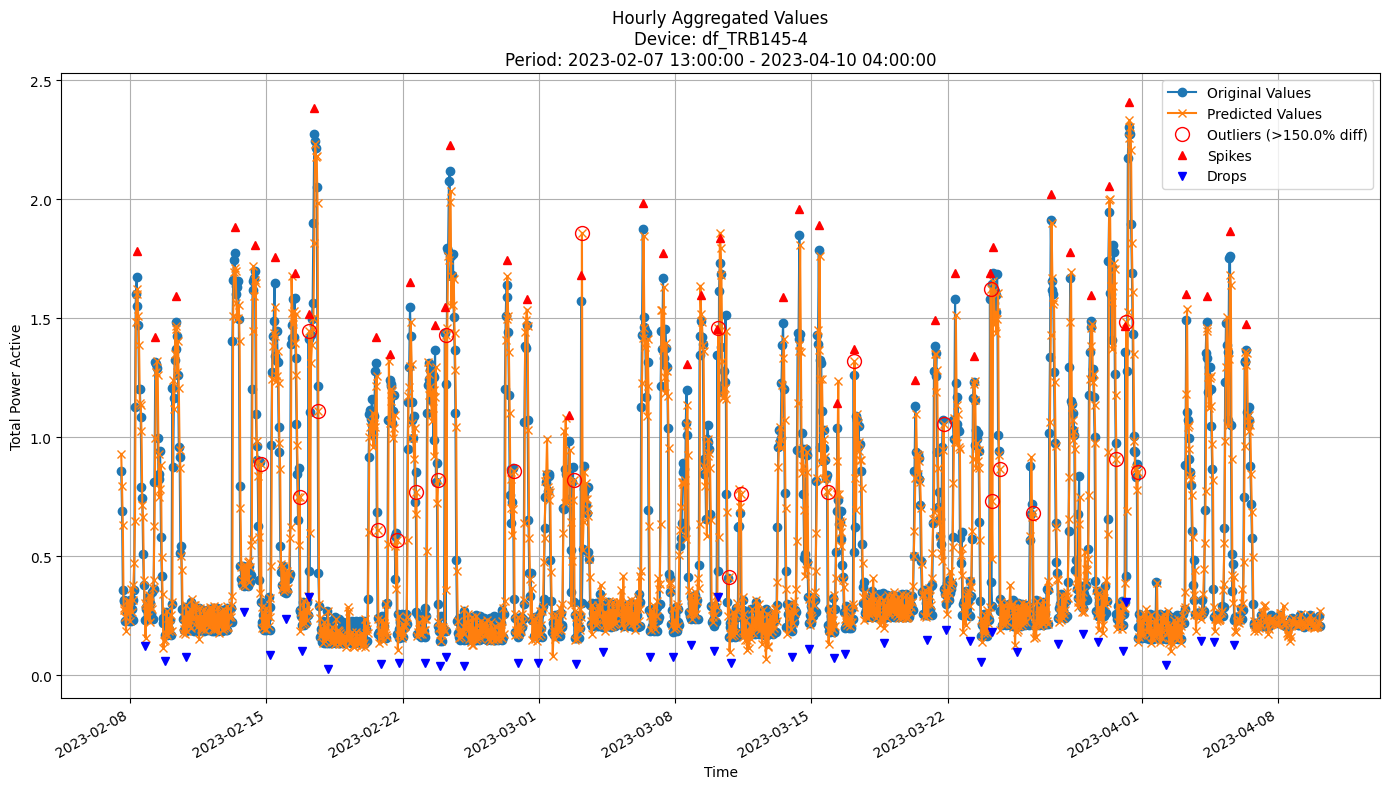


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2092
MAE: 0.1210
MAPE: 28.6234%

Directional Metrics:
Directional Accuracy: 39.7835%
First-Diff Correlation: 0.0230

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1750
  Recall: 0.1522
  F1 Score: 0.1628
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9000
  Recall: 0.7826
  F1 Score: 0.8372
Drops:
  Precision: 0.3846
  Recall: 0.3333
  F1 Score: 0.3571


In [34]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [35]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT

fodt_params = {'depth': 50, 
               'grace_period': 24, 
               'grace_period_depth': 0, 
               'split_confidence': 0.005, 
               'max_feature': 0.3, 
               'tie_threshold': 0.05, 
               'bin_type': 'mean', 
               'split_criterion': 'vr_rel'}

In [ ]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt, 
    model_params=fodt_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 0.026154 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2595
	MAE: 0.1520
	MAPE: 17.7243%

Directional Metrics:
	Directional Accuracy: 34.2772%
	First-Diff Correlation: -0.0349

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0667
		Recall: 0.0769
		F1: 0.0714

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8667
		Recall: 1.0000
		F1: 0.9286
	Drops:
		Precision: 0.6000
		Recall: 0.6923
		F1: 0.6429
---------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 0.181183 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2426
	MAE: 0.1493
	MAPE: 28.6991%

Directional Metrics:
	Directional Accuracy: 41.2817%
	First-Diff Correlation: 0.2282

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 0.057449 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2286
	MAE: 0.1431
	MAPE: 33.5971%

Directional Metrics:
	Directional Accuracy: 40.5365%
	First-Diff Correlation: -0.0174

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1053
		F1: 0.1212
	Drops:
		Precision: 0.0714
		Recall: 0.0500
		F1: 0.0588

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7368
		F1: 0.8485
	Drops:
		Precision: 0.3571
		Recall: 0.2500
		F1: 0.2941
---------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 2.594154 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1794
	MAE: 0.0903
	MAPE: 23.1756%

Directional Metrics:
	Directional Accuracy: 43.2836%
	First-Diff Correlation: 0.3752

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6000
		Recall: 1.0000
		F1: 0.7500
	Drops:
		Precision: 0.3333
		Recall: 0.6667
		F1: 0.4444
----------------------------------------------

#### Results

In [37]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2453 ± 0.0235
	MAE: 0.1422 ± 0.0161
	MAPE: 27.8780% ± 4.8668%

	Directional Metrics:
		Directional Accuracy: 40.6994% ± 2.7456%
		First-Diff Correlation: 0.0927 ± 0.0826

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0068 ± 0.0167
		Drop Recall: 0.0040 ± 0.0097
		Drop F1: 0.0050 ± 0.0123

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6823 ± 0.4341
		Spike Recall: 0.3411 ± 0.3387
		Spike F1: 0.4149 ± 0.3554
		Drop Precision: 0.1932 ± 0.3433
		Drop Recall: 0.1696 ± 0.3437
		Drop F1: 0.1774 ± 0.3433
Daily Metrics:
	RMSE: 1.2155 ± 0.9196
	MAE: 0.8512 ± 0.5022
	MAPE: 7.5281% ± 3.9849%

	Directional Metrics:
		Directional Accuracy: 93.2422% ± 6.5590%
		First-Diff Correlation: 0.9877 ± 0.0194

	Immediate Detection (delta=0):


#### Training plots


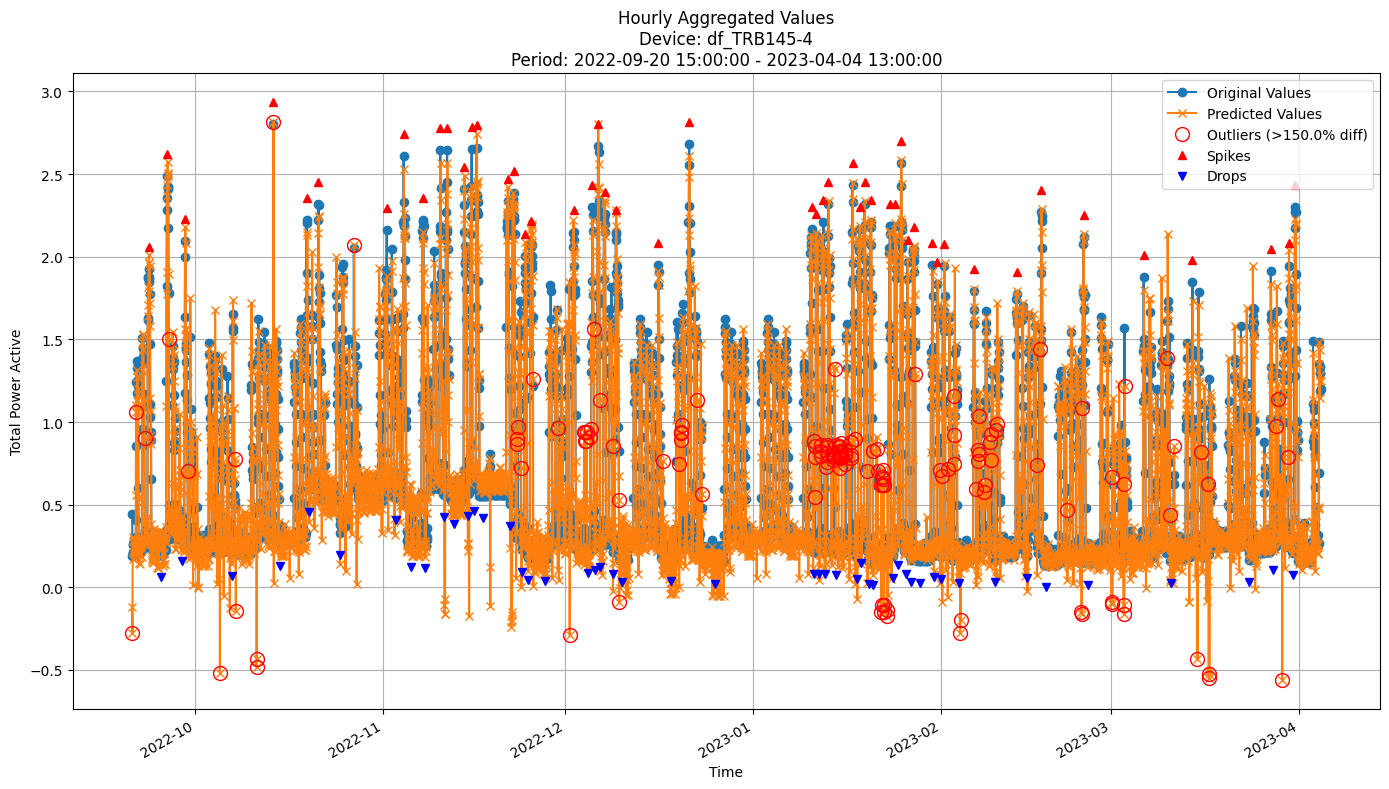


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2340
MAE: 0.1441
MAPE: 32.1655%

Directional Metrics:
Directional Accuracy: 45.4275%
First-Diff Correlation: 0.2037

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8667
  Recall: 0.2600
  F1 Score: 0.4000
Drops:
  Precision: 0.0667
  Recall: 0.0204
  F1 Score: 0.0312


In [38]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

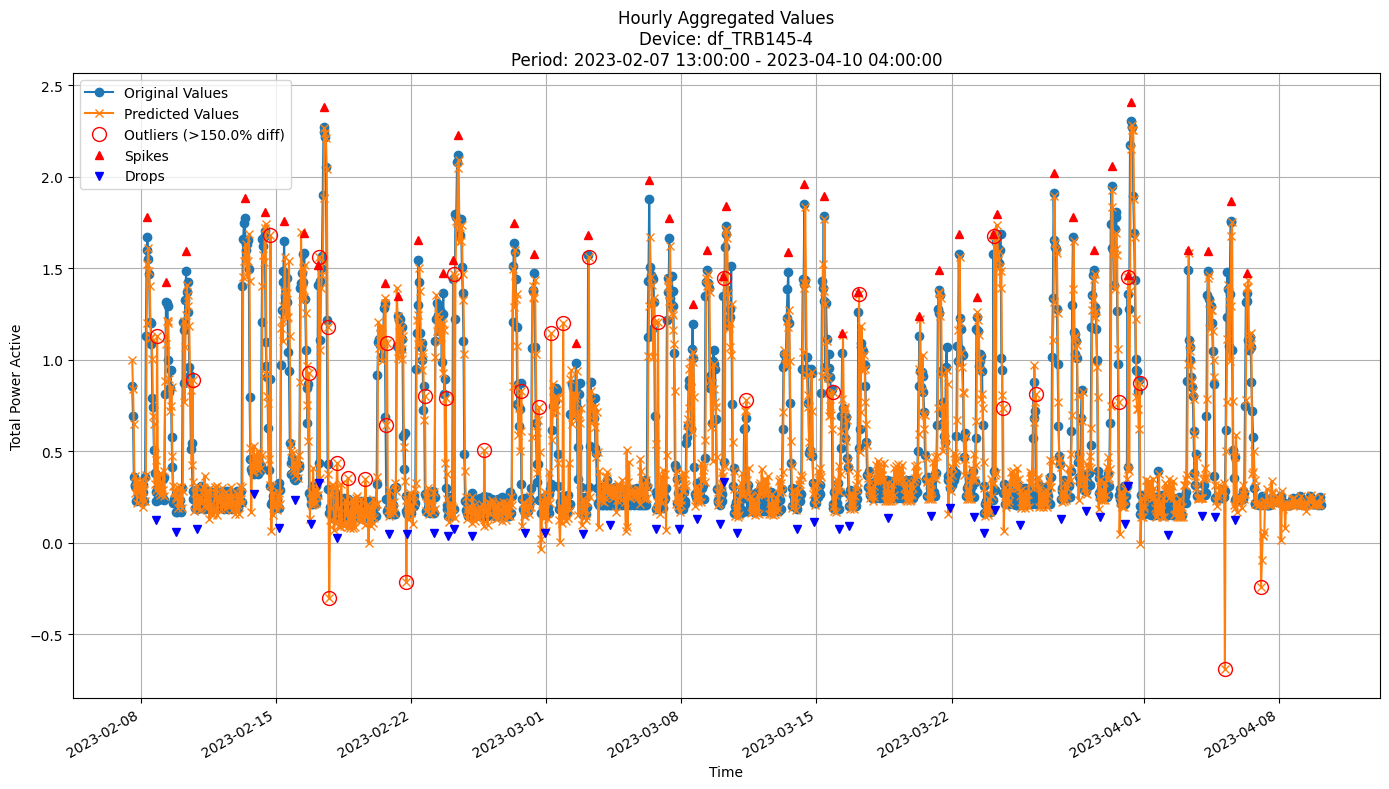


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2339
MAE: 0.1398
MAPE: 35.2434%

Directional Metrics:
Directional Accuracy: 39.3099%
First-Diff Correlation: 0.0276

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0541
  Recall: 0.0435
  F1 Score: 0.0482
Drops:
  Precision: 0.0278
  Recall: 0.0222
  F1 Score: 0.0247

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8649
  Recall: 0.6957
  F1 Score: 0.7711
Drops:
  Precision: 0.3056
  Recall: 0.2444
  F1 Score: 0.2716


In [39]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [40]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = dict(n_models=20, 
                  aggregation_method="mean", 
                  grace_period=0,  # by default works for all leaves
                  disable_weighted_vote=True,
                  max_depth=50, 
                  delta=0.05, 
                  tau=0.01, 
                  seed=42, 
                  max_features=0.7, 
                  bin_type='mean', 
                  max_bins=1,
                  split_criterion='vr_rel',)


In [ ]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 394.100433 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2903
	MAE: 0.1753
	MAPE: 21.4675%

Directional Metrics:
	Directional Accuracy: 46.0507%
	First-Diff Correlation: 0.0978

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2500
		Recall: 0.1538
		F1: 0.1905
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7500
		Recall: 0.4615
		F1: 0.5714
	Drops:
		Precision: 0.2500
		Recall: 0.1538
		F1: 0.1905
--------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 597.462234 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2404
	MAE: 0.1547
	MAPE: 28.6593%

Directional Metrics:
	Directional Accuracy: 47.9881%
	First-Diff Correlation: 0.3448

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 1472.554276 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2390
	MAE: 0.1498
	MAPE: 34.7270%

Directional Metrics:
	Directional Accuracy: 47.8390%
	First-Diff Correlation: 0.2045

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.5000
		Recall: 0.4211
		F1: 0.4571
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9375
		Recall: 0.7895
		F1: 0.8571
	Drops:
		Precision: 0.2941
		Recall: 0.2500
		F1: 0.2703
-------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 1516.681625 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2428
	MAE: 0.1386
	MAPE: 46.3145%

Directional Metrics:
	Directional Accuracy: 52.2388%
	First-Diff Correlation: 0.2758

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.3333
		F1: 0.2500
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6000
		Recall: 1.0000
		F1: 0.7500
	Drops:
		Precision: 0.1667
		Recall: 0.3333
		F1: 0.2222
-------------------------------------------

#### Results

In [42]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2516 ± 0.0331
	MAE: 0.1308 ± 0.0113
	MAPE: 24.6490% ± 3.4662%

	Directional Metrics:
		Directional Accuracy: 54.3826% ± 3.3910%
		First-Diff Correlation: 0.2530 ± 0.0653

	Immediate Detection (delta=0):
		Spike Precision: 0.0987 ± 0.0895
		Spike Recall: 0.1765 ± 0.1667
		Spike F1: 0.1127 ± 0.0945
		Drop Precision: 0.0154 ± 0.0314
		Drop Recall: 0.0180 ± 0.0363
		Drop F1: 0.0166 ± 0.0337

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3592 ± 0.3054
		Spike Recall: 0.5440 ± 0.3842
		Spike F1: 0.4005 ± 0.3197
		Drop Precision: 0.1223 ± 0.1363
		Drop Recall: 0.1447 ± 0.1582
		Drop F1: 0.1325 ± 0.1464
Daily Metrics:
	RMSE: 0.8238 ± 0.4157
	MAE: 0.5222 ± 0.1511
	MAPE: 3.3238% ± 1.2920%

	Directional Metrics:
		Directional Accuracy: 93.4876% ± 1.1857%
		First-Diff Correlation: 0.9889 ± 0.0148

	Immediate Detection (delta=0):


#### Training plots

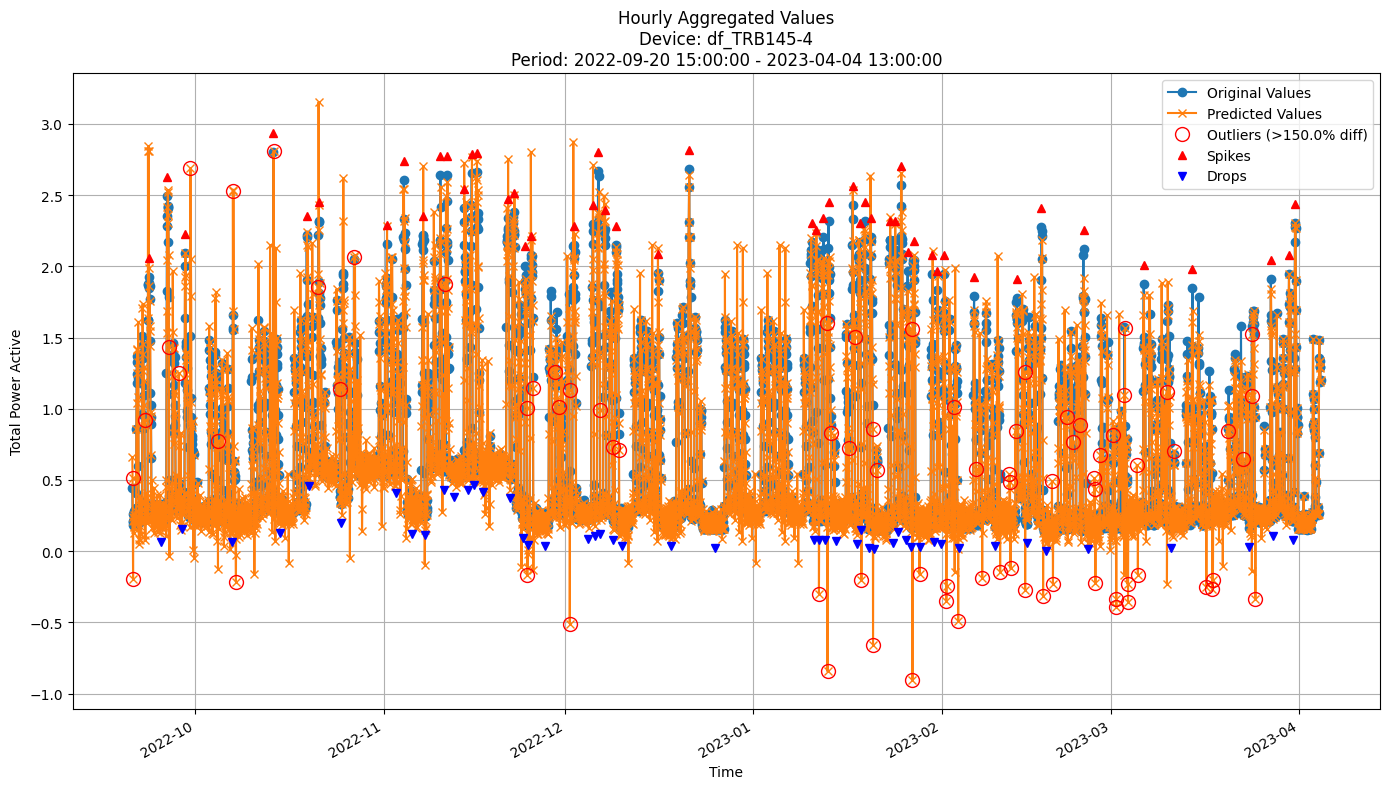


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2381
MAE: 0.1356
MAPE: 26.9929%

Directional Metrics:
Directional Accuracy: 53.3815%
First-Diff Correlation: 0.2568

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0820
  Recall: 0.1000
  F1 Score: 0.0901
Drops:
  Precision: 0.0167
  Recall: 0.0204
  F1 Score: 0.0183

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4426
  Recall: 0.5400
  F1 Score: 0.4865
Drops:
  Precision: 0.1333
  Recall: 0.1633
  F1 Score: 0.1468


In [43]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

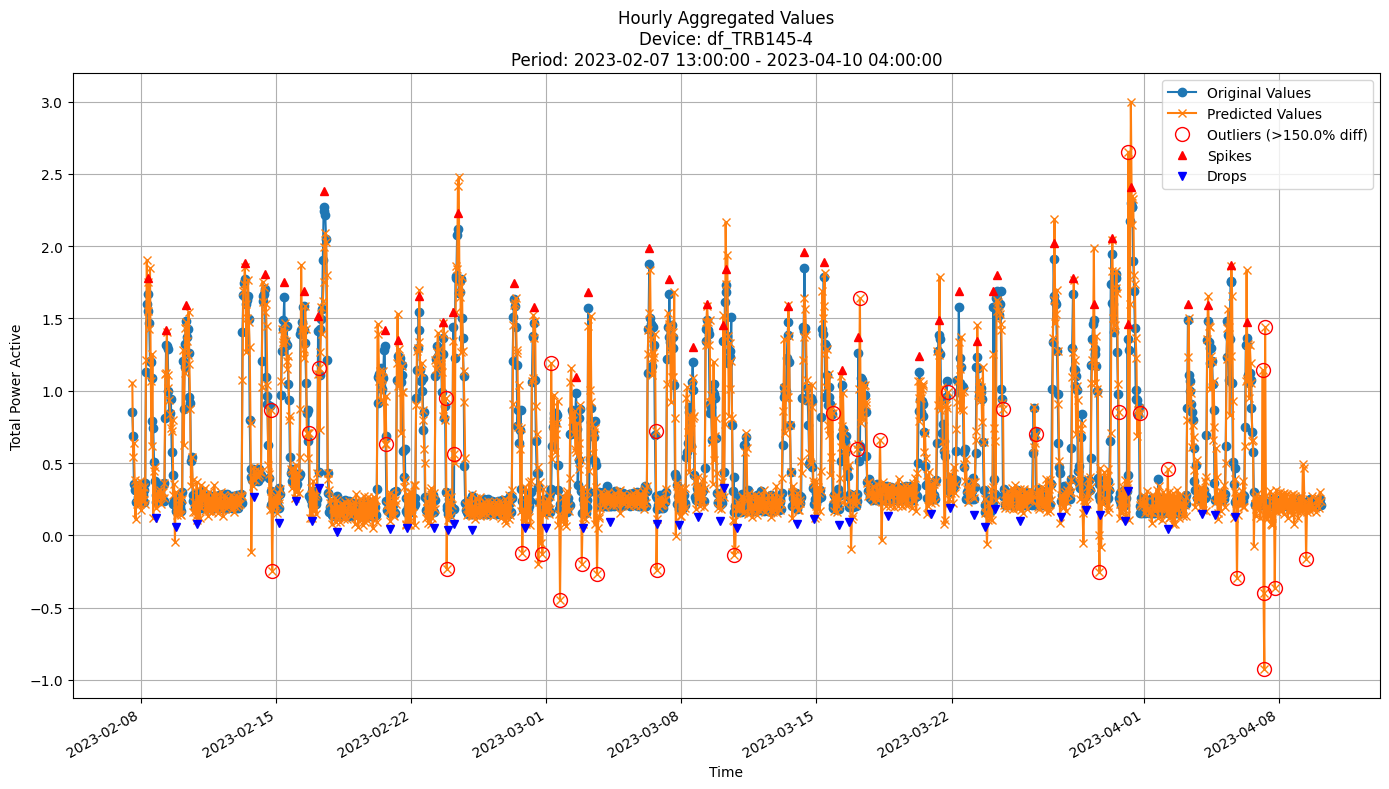


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2191
MAE: 0.1373
MAPE: 34.6940%

Directional Metrics:
Directional Accuracy: 49.4587%
First-Diff Correlation: 0.3002

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3250
  Recall: 0.2826
  F1 Score: 0.3023
Drops:
  Precision: 0.0513
  Recall: 0.0444
  F1 Score: 0.0476

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7000
  Recall: 0.6087
  F1 Score: 0.6512
Drops:
  Precision: 0.2821
  Recall: 0.2444
  F1 Score: 0.2619


In [44]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

split_confidence_hf = 0.01
grace_period = 24
depth = 50
eagerness = 0
bin_type = 'mean'  # 'mean' or 'adaptive'
max_bins = 1
# max_bins = 32  # for adaptive binning
max_features = 0.7
tie_threshold = 0.05
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes

incb = IncubationBoost
incb_params = dict(
    length=20,
    learning_rate=0.5,
    depth=depth,
    grace_period=grace_period,
    split_confidence=split_confidence_hf,
    eagerness=eagerness,
    grace_period_depth=grace_period_depth,
    bin_type=bin_type,
    max_bins=max_bins,
    max_feature=max_features,
    tie_threshold=tie_threshold,
    split_criterion='vr_rel',
    verbose=False
)

In [ ]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 0.143936 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2581
	MAE: 0.1523
	MAPE: 17.7395%

Directional Metrics:
	Directional Accuracy: 34.1282%
	First-Diff Correlation: -0.0282

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9286
		Recall: 1.0000
		F1: 0.9630
	Drops:
		Precision: 0.5714
		Recall: 0.6154
		F1: 0.5926
---------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 0.676018 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2311
	MAE: 0.1351
	MAPE: 23.5699%

Directional Metrics:
	Directional Accuracy: 42.0268%
	First-Diff Correlation: 0.2634

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 1.449654 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2327
	MAE: 0.1387
	MAPE: 31.3002%

Directional Metrics:
	Directional Accuracy: 37.4069%
	First-Diff Correlation: -0.0156

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0556
		Recall: 0.0526
		F1: 0.0541
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8889
		Recall: 0.8421
		F1: 0.8649
	Drops:
		Precision: 0.3158
		Recall: 0.3000
		F1: 0.3077
---------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 0.655746 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1253
	MAE: 0.0523
	MAPE: 10.1638%

Directional Metrics:
	Directional Accuracy: 44.7761%
	First-Diff Correlation: 0.5354

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
----------------------------------------------

#### Results

In [47]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2336 ± 0.0160
	MAE: 0.1309 ± 0.0101
	MAPE: 23.6090% ± 1.6067%

	Directional Metrics:
		Directional Accuracy: 40.8096% ± 1.2708%
		First-Diff Correlation: 0.0885 ± 0.0767

	Immediate Detection (delta=0):
		Spike Precision: 0.0037 ± 0.0090
		Spike Recall: 0.0029 ± 0.0070
		Spike F1: 0.0032 ± 0.0079
		Drop Precision: 0.0073 ± 0.0179
		Drop Recall: 0.0058 ± 0.0143
		Drop F1: 0.0065 ± 0.0159

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5978 ± 0.4445
		Spike Recall: 0.5455 ± 0.3868
		Spike F1: 0.5235 ± 0.3657
		Drop Precision: 0.3016 ± 0.3378
		Drop Recall: 0.2466 ± 0.3332
		Drop F1: 0.2673 ± 0.3338
Daily Metrics:
	RMSE: 0.5629 ± 0.3325
	MAE: 0.4456 ± 0.3214
	MAPE: 3.7186% ± 2.3905%

	Directional Metrics:
		Directional Accuracy: 95.9147% ± 3.2137%
		First-Diff Correlation: 0.9986 ± 0.0012

	Immediate Detection (delta=0):


#### Train plots

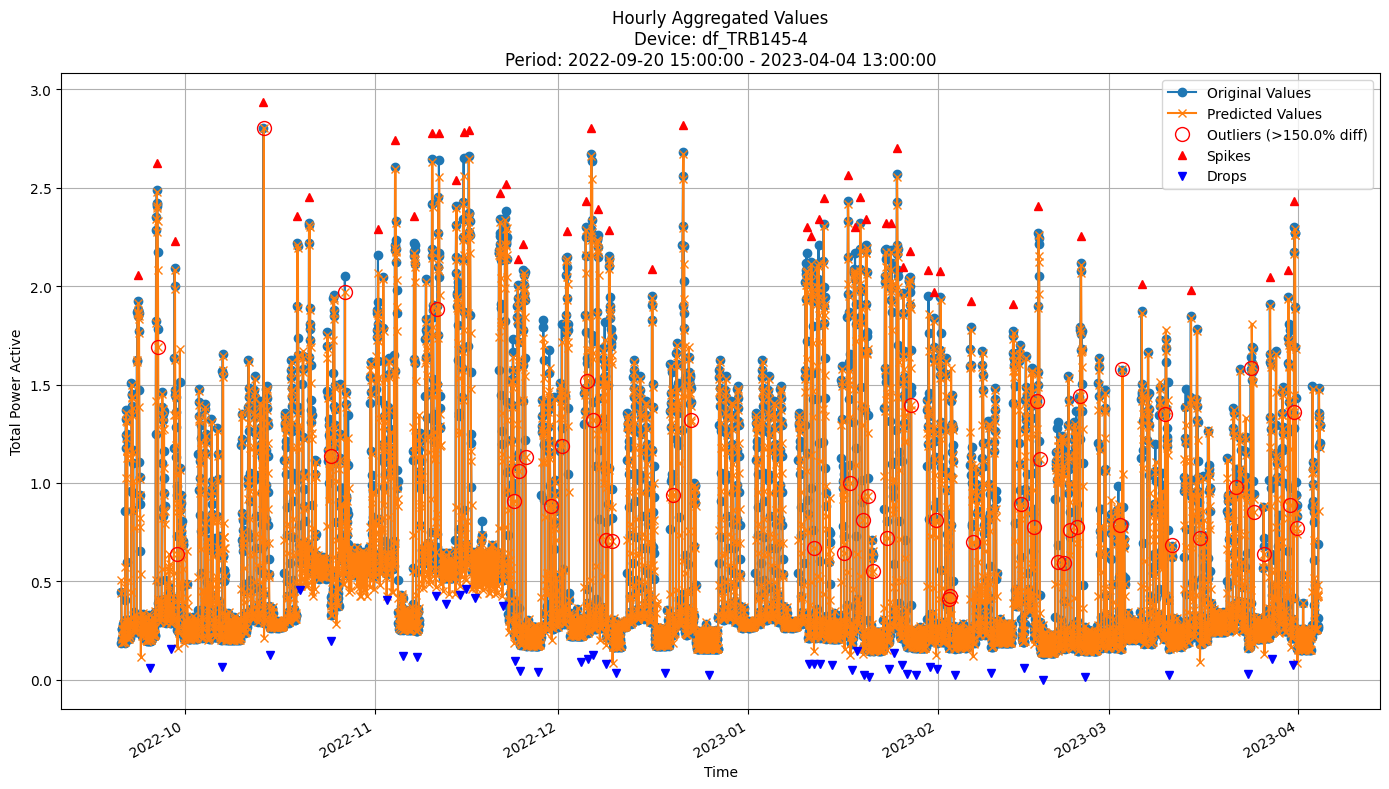


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2185
MAE: 0.1248
MAPE: 24.4420%

Directional Metrics:
Directional Accuracy: 39.9617%
First-Diff Correlation: 0.1430

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0256
  Recall: 0.0200
  F1 Score: 0.0225
Drops:
  Precision: 0.0513
  Recall: 0.0408
  F1 Score: 0.0455

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9487
  Recall: 0.7400
  F1 Score: 0.8315
Drops:
  Precision: 0.4615
  Recall: 0.3673
  F1 Score: 0.4091


In [48]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

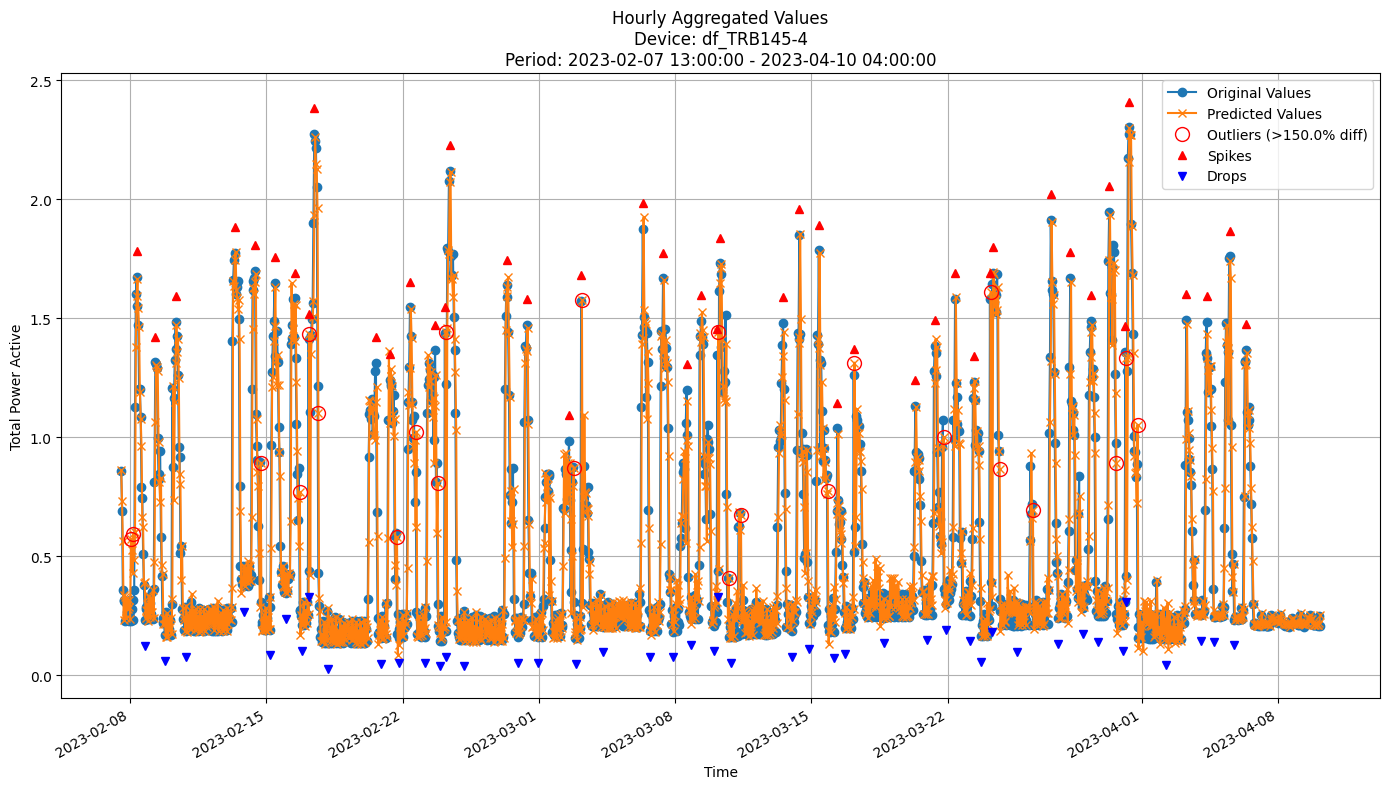


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2173
MAE: 0.1252
MAPE: 29.3782%

Directional Metrics:
Directional Accuracy: 36.8742%
First-Diff Correlation: 0.0170

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0465
  Recall: 0.0435
  F1 Score: 0.0449
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9070
  Recall: 0.8478
  F1 Score: 0.8764
Drops:
  Precision: 0.5000
  Recall: 0.4667
  F1 Score: 0.4828


In [49]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [ ]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    arf_params,
    incb_params,
 ]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        use_residuals=USE_RESIDUAL,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=ALL_FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-04-10 04:00:00+02:00
Model's memory usage: 0.000458 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 20:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2078
	MAE: 0.0964
	MAPE: 16.4499%

Directional Metrics:
	Directional Accuracy: 48.8468%
	First-Diff Correlation: 0.1843

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
----------------------------------------------

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-04-10 04:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2023-04-10 06:00:00+02:00 to 2023-04-24 06:00:00+02:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-04-24 06:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-04-24 07:00:00+02:00 to 2023-05-08 07:00:00+02:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-05-08 07:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-05-08 08:00:00+02:00 to 2023-05-22 08:00:00+02:00

-------------------------

Retraining model on data from 2022-09-20 15:00:00+02:00 to 2023-05-22 08:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2023-05-22 09:00:00+02:00 to 2023-05-30 20:00:00+02:00

-------------------------
Model's memory usage: 0.024338 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 20:00:00+02:00
--------------

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (9 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-04-10 04:00:00+02:00
Model's memory usage: 1909.461876 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 20:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2048
	MAE: 0.1024
	MAPE: 21.0865%

Directional Metrics:
	Directional Accuracy: 56.7545%
	First-Diff Correlation: 0.2696

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2708
		Recall: 0.2889
		F1: 0.2796
	Drops:
		Precision: 0.1020
		Recall: 0.1136
		F1: 0.1075

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7708
		Recall: 0.8222
		F1: 0.7957
	Drops:
		Precision: 0.2857
		Recall: 0.3182
		F1: 0.3011
-------------------------------------------

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 15:00:00+02:00 to 2023-04-10 04:00:00+02:00
Model's memory usage: 2.199966 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 20:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1891
	MAE: 0.0880
	MAPE: 15.6535%

Directional Metrics:
	Directional Accuracy: 49.7529%
	First-Diff Correlation: 0.2121

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2222
		Recall: 0.2222
		F1: 0.2222
	Drops:
		Precision: 0.0455
		Recall: 0.0455
		F1: 0.0455

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.4773
		Recall: 0.4773
		F1: 0.4773
----------------------------------------------

In [51]:
for model_class in models_classes:
    model_test_results[model_class.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model_class.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [52]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [53]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [54]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [55]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.208 ± 0.000,0.096 ± 0.000,16.450 ± 0.000,48.847 ± 0.000,18.428 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.190 ± 0.000,0.099 ± 0.000,22.004 ± 0.000,55.766 ± 0.000,29.958 ± 0.000,38.202 ± 0.000,80.899 ± 0.000,4.545 ± 0.000,29.545 ± 0.000
2,GBDT,0.173 ± 0.000,0.089 ± 0.000,17.972 ± 0.000,48.764 ± 0.000,29.129 ± 0.000,26.190 ± 0.000,90.476 ± 0.000,4.878 ± 0.000,29.268 ± 0.000
3,RandomForest,0.167 ± 0.000,0.082 ± 0.000,15.932 ± 0.000,51.318 ± 0.000,28.014 ± 0.000,27.273 ± 0.000,97.727 ± 0.000,4.651 ± 0.000,30.233 ± 0.000
4,HoeffdingTree,0.198 ± 0.000,0.106 ± 0.000,21.456 ± 0.000,51.647 ± 0.000,21.496 ± 0.000,18.824 ± 0.000,80.000 ± 0.000,0.000 ± 0.000,36.145 ± 0.000
5,ARF_Hoeffding,0.186 ± 0.000,0.088 ± 0.000,16.294 ± 0.000,50.494 ± 0.000,21.899 ± 0.000,11.364 ± 0.000,95.455 ± 0.000,6.977 ± 0.000,37.209 ± 0.000
6,FastODT,0.256 ± 0.000,0.132 ± 0.000,27.858 ± 0.000,50.494 ± 0.000,14.629 ± 0.000,24.299 ± 0.000,71.028 ± 0.000,3.774 ± 0.000,35.849 ± 0.000
7,ARF_FastODT,0.205 ± 0.000,0.102 ± 0.000,21.087 ± 0.000,56.755 ± 0.000,26.959 ± 0.000,27.957 ± 0.000,79.570 ± 0.000,10.753 ± 0.000,30.108 ± 0.000
8,IncubationBoost,0.189 ± 0.000,0.088 ± 0.000,15.653 ± 0.000,49.753 ± 0.000,21.207 ± 0.000,22.222 ± 0.000,100.000 ± 0.000,4.545 ± 0.000,47.727 ± 0.000


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.208 ± 0.000</td>
      <td>0.096 ± 0.000</td>
      <td>16.450 ± 0.000</td>
      <td>48.847 ± 0.000</td>
      <td>18.428 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.190 ± 0.000</td>
      <td>0.099 ± 0.000</td>
      <td>22.004 ± 0.000</td>
      <td>55.766 ± 0.000</td>
      <td>29.958 ± 0.000</td>
      <td>38.202 ± 0.000</td>
      <td>80.899 ± 0.000</td>
      <td>4.545 ± 0.000</td>
      <td>29.545 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.173 ± 0.000</td>
      <td>0.089 ± 0.000</td>
      <td>17.972 ± 0.000</td>
      <td>48.764 ± 0.000</td>
      <td>29.129 ± 0.000</td>
      <td>26.190 ± 0.000</td>
      <td>90.476 ± 0.000</td>
      <td>4.878 ± 0.000</td>
      <td>29.268 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.167 ± 0.000</td>
      <td>0.082 ± 0.000</td>
      <td>15.932 ± 0.000</td>
      <td>51.318 ± 0.000</td>
      <td>28.014 ± 0.000</td>
      <td>27.273 ± 0.000</td>
      <td>97.727 ± 0.000</td>
      <td>4.651 ± 0.000</td>
      <td>30.233 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.198 ± 0.000</td>
      <td>0.106 ± 0.000</td>
      <td>21.456 ± 0.000</td>
      <td>51.647 ± 0.000</td>
      <td>21.496 ± 0.000</td>
      <td>18.824 ± 0.000</td>
      <td>80.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>36.145 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.186 ± 0.000</td>
      <td>0.088 ± 0.000</td>
      <td>16.294 ± 0.000</td>
      <td>50.494 ± 0.000</td>
      <td>21.899 ± 0.000</td>
      <td>11.364 ± 0.000</td>
      <td>95.455 ± 0.000</td>
      <td>6.977 ± 0.000</td>
      <td>37.209 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.212 ± 0.000</td>
      <td>0.110 ± 0.000</td>
      <td>22.189 ± 0.000</td>
      <td>49.835 ± 0.000</td>
      <td>18.696 ± 0.000</td>
      <td>22.917 ± 0.000</td>
      <td>85.417 ± 0.000</td>
      <td>4.255 ± 0.000</td>
      <td>36.170 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.205 ± 0.000</td>
      <td>0.102 ± 0.000</td>
      <td>21.087 ± 0.000</td>
      <td>56.755 ± 0.000</td>
      <td>26.959 ± 0.000</td>
      <td>27.957 ± 0.000</td>
      <td>79.570 ± 0.000</td>
      <td>10.753 ± 0.000</td>
      <td>30.108 ± 0.000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.188 ± 0.000</td>
      <td>0.088 ± 0.000</td>
      <td>16.070 ± 0.000</td>
      <td>48.847 ± 0.000</td>
      <td>23.186 ± 0.000</td>
      <td>10.989 ± 0.000</td>
      <td>98.901 ± 0.000</td>
      <td>6.742 ± 0.000</td>
      <td>47.191 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

## Validation results

In [56]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.227 ± 0.042,0.128 ± 0.031,23.862 ± 7.597,39.183 ± 4.839,18.652 ± 19.926,0.000 ± 0.000,85.714 ± 34.993,0.000 ± 0.000,85.253 ± 34.822
1,BL_Mean,0.189 ± 0.041,0.117 ± 0.029,25.727 ± 5.448,45.743 ± 8.879,28.821 ± 19.767,20.717 ± 16.118,63.929 ± 30.776,3.378 ± 4.113,28.702 ± 25.055
2,GBDT,0.201 ± 0.040,0.119 ± 0.036,24.945 ± 5.082,43.505 ± 6.421,27.555 ± 15.964,11.530 ± 12.847,57.061 ± 38.309,0.733 ± 1.794,21.455 ± 14.867
3,RandomForest,0.117 ± 0.010,0.069 ± 0.007,13.657 ± 1.793,48.332 ± 6.259,65.099 ± 5.727,12.706 ± 15.608,43.963 ± 39.491,6.683 ± 7.236,11.346 ± 11.115
4,HoeffdingTree,0.211 ± 0.042,0.129 ± 0.027,27.697 ± 6.308,42.207 ± 4.036,21.614 ± 18.275,16.159 ± 14.655,70.606 ± 31.123,0.000 ± 0.000,26.992 ± 13.409
5,ARF_Hoeffding,0.198 ± 0.044,0.115 ± 0.030,22.913 ± 6.622,42.017 ± 6.802,23.203 ± 21.768,12.276 ± 11.083,76.743 ± 32.211,2.765 ± 6.773,39.297 ± 20.148
6,FastODT,0.224 ± 0.033,0.133 ± 0.024,28.456 ± 7.094,41.248 ± 4.310,19.066 ± 17.826,2.653 ± 4.460,69.862 ± 30.596,3.326 ± 4.025,33.619 ± 24.564
7,ARF_FastODT,0.226 ± 0.039,0.139 ± 0.026,31.303 ± 7.977,50.831 ± 5.322,32.192 ± 12.723,21.880 ± 15.440,56.239 ± 25.923,6.463 ± 9.844,27.376 ± 16.032
8,IncubationBoost,0.208 ± 0.042,0.120 ± 0.032,23.391 ± 7.701,40.078 ± 5.206,21.529 ± 20.933,6.427 ± 11.277,79.354 ± 32.795,0.752 ± 1.842,45.238 ± 28.537


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.227 ± 0.042</td>
      <td>0.128 ± 0.031</td>
      <td>23.862 ± 7.597</td>
      <td>39.183 ± 4.839</td>
      <td>18.652 ± 19.926</td>
      <td>0.000 ± 0.000</td>
      <td>85.714 ± 34.993</td>
      <td>0.000 ± 0.000</td>
      <td>85.253 ± 34.822</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.189 ± 0.041</td>
      <td>0.117 ± 0.029</td>
      <td>25.727 ± 5.448</td>
      <td>45.743 ± 8.879</td>
      <td>28.821 ± 19.767</td>
      <td>20.717 ± 16.118</td>
      <td>63.929 ± 30.776</td>
      <td>3.378 ± 4.113</td>
      <td>28.702 ± 25.055</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.201 ± 0.040</td>
      <td>0.119 ± 0.036</td>
      <td>24.945 ± 5.082</td>
      <td>43.505 ± 6.421</td>
      <td>27.555 ± 15.964</td>
      <td>11.530 ± 12.847</td>
      <td>57.061 ± 38.309</td>
      <td>0.733 ± 1.794</td>
      <td>21.455 ± 14.867</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.117 ± 0.010</td>
      <td>0.069 ± 0.007</td>
      <td>13.657 ± 1.793</td>
      <td>48.332 ± 6.259</td>
      <td>65.099 ± 5.727</td>
      <td>12.706 ± 15.608</td>
      <td>43.963 ± 39.491</td>
      <td>6.683 ± 7.236</td>
      <td>11.346 ± 11.115</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.211 ± 0.042</td>
      <td>0.129 ± 0.027</td>
      <td>27.697 ± 6.308</td>
      <td>42.207 ± 4.036</td>
      <td>21.614 ± 18.275</td>
      <td>16.159 ± 14.655</td>
      <td>70.606 ± 31.123</td>
      <td>0.000 ± 0.000</td>
      <td>26.992 ± 13.409</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.198 ± 0.044</td>
      <td>0.115 ± 0.030</td>
      <td>22.913 ± 6.622</td>
      <td>42.017 ± 6.802</td>
      <td>23.203 ± 21.768</td>
      <td>12.276 ± 11.083</td>
      <td>76.743 ± 32.211</td>
      <td>2.765 ± 6.773</td>
      <td>39.297 ± 20.148</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.225 ± 0.039</td>
      <td>0.132 ± 0.029</td>
      <td>26.782 ± 8.276</td>
      <td>43.252 ± 6.035</td>
      <td>20.534 ± 17.332</td>
      <td>9.012 ± 12.607</td>
      <td>65.916 ± 33.154</td>
      <td>1.704 ± 2.721</td>
      <td>28.086 ± 22.909</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.226 ± 0.039</td>
      <td>0.139 ± 0.026</td>
      <td>31.303 ± 7.977</td>
      <td>50.831 ± 5.322</td>
      <td>32.192 ± 12.723</td>
      <td>21.880 ± 15.440</td>
      <td>56.239 ± 25.923</td>
      <td>6.463 ± 9.844</td>
      <td>27.376 ± 16.032</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.207 ± 0.043</td>
      <td>0.118 ± 0.032</td>
      <td>22.986 ± 7.411</td>
      <td>40.461 ± 4.427</td>
      <td>21.677 ± 19.850</td>
      <td>4.167 ± 6.682</td>
      <td>78.313 ± 32.205</td>
      <td>5.700 ± 7.946</td>
      <td>49.131 ± 28.542</td>
    </tr>
  </tbody>
</table>
</div>

### By-period validation results

In [57]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Mean": bl_prev_valid_period_metrics,
    "BL_Prev": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [58]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,34.426,42.474,42.772,35.917,40.537,33.085,34.277,46.051,34.128,38.185222
Period 2,39.642,43.666,44.709,41.133,40.387,40.387,41.282,47.988,42.027,42.357889
Period 3,50.075,63.040,57.526,50.522,49.180,51.416,48.584,63.040,49.478,53.651222
Period 4,36.662,40.835,42.772,38.152,38.897,39.344,43.666,48.137,38.003,40.718667
Period 5,35.768,35.320,40.984,37.109,40.089,38.748,37.109,50.522,34.724,38.930333
Period 6,37.407,40.387,34.724,35.618,38.599,38.152,40.537,47.839,37.407,38.963333
Period 7,40.299,54.478,41.045,52.985,47.761,52.985,43.284,52.239,44.776,47.761333



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,5.216,1.192,1.937,5.216,-0.150,7.302,7.005,1.937,7.899,4.173
Period 3 - Period 2,10.433,19.374,12.817,9.389,8.793,11.029,7.302,15.052,7.451,11.293
Period 4 - Period 3,-13.413,-22.205,-14.754,-12.370,-10.283,-12.072,-4.918,-14.903,-11.475,-12.933
Period 5 - Period 4,-0.894,-5.515,-1.788,-1.043,1.192,-0.596,-6.557,2.385,-3.279,-1.788
Period 6 - Period 5,1.639,5.067,-6.260,-1.491,-1.490,-0.596,3.428,-2.683,2.683,0.033
Period 7 - Period 6,2.892,14.091,6.321,17.367,9.162,14.833,2.747,4.400,7.369,8.798


#### MAPE (lower is better)

In [59]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,17.513,19.432,25.049,19.583,18.746,17.141,17.724,21.468,17.740,19.377333
Period 2,23.358,25.755,28.006,27.208,26.145,22.829,28.699,28.659,23.570,26.025444
Period 3,19.095,16.906,17.583,16.980,20.480,16.517,22.646,21.521,18.548,18.919556
Period 4,32.108,29.754,26.814,27.568,34.124,29.814,34.035,34.108,31.100,31.047222
Period 5,32.711,32.604,28.567,28.596,35.787,30.118,39.314,32.327,31.316,32.371111
Period 6,30.593,30.827,31.360,29.755,33.303,30.091,33.597,34.727,31.300,31.728111
Period 7,11.654,24.812,17.235,11.946,25.293,13.877,23.176,46.314,10.164,20.496778



Absolute gain/drop in MAPE (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,5.845,6.323,2.957,7.625,7.399,5.688,10.975,7.191,5.830,6.648
Period 3 - Period 2,-4.263,-8.849,-10.423,-10.228,-5.665,-6.312,-6.053,-7.138,-5.022,-7.106
Period 4 - Period 3,13.013,12.848,9.231,10.588,13.644,13.297,11.389,12.587,12.552,12.128
Period 5 - Period 4,0.603,2.850,1.753,1.028,1.663,0.304,5.279,-1.781,0.216,1.324
Period 6 - Period 5,-2.118,-1.777,2.793,1.159,-2.484,-0.027,-5.717,2.400,-0.016,-0.643
Period 7 - Period 6,-18.939,-6.015,-14.125,-17.809,-8.010,-16.214,-10.421,11.587,-21.136,-11.231


#### RMSE (lower is better)

In [60]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.257,0.258,0.277,0.234,0.253,0.242,0.260,0.290,0.258,0.258778
Period 2,0.254,0.213,0.227,0.208,0.244,0.231,0.243,0.240,0.231,0.232333
Period 3,0.179,0.123,0.171,0.134,0.147,0.150,0.168,0.156,0.168,0.155111
Period 4,0.271,0.196,0.191,0.190,0.239,0.219,0.238,0.220,0.227,0.221222
Period 5,0.238,0.177,0.193,0.192,0.227,0.213,0.248,0.192,0.216,0.210667
Period 6,0.242,0.206,0.207,0.208,0.225,0.220,0.229,0.239,0.233,0.223222
Period 7,0.147,0.150,0.141,0.114,0.145,0.114,0.179,0.243,0.125,0.150889



Absolute gain/drop in RMSE:


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.003,-0.045,-0.050,-0.026,-0.009,-0.011,-0.017,-0.050,-0.027,-0.026
Period 3 - Period 2,-0.075,-0.090,-0.056,-0.074,-0.097,-0.081,-0.075,-0.084,-0.063,-0.077
Period 4 - Period 3,0.092,0.073,0.020,0.056,0.092,0.069,0.070,0.064,0.059,0.066
Period 5 - Period 4,-0.033,-0.019,0.002,0.002,-0.012,-0.006,0.010,-0.028,-0.011,-0.011
Period 6 - Period 5,0.004,0.029,0.014,0.016,-0.002,0.007,-0.019,0.047,0.017,0.013
Period 7 - Period 6,-0.095,-0.056,-0.066,-0.094,-0.080,-0.106,-0.050,0.004,-0.108,-0.072
